In [1]:
import pandas as pd
import seaborn as sns
import matplotlib
matplotlib.use("Agg") 
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
from threading import Thread

cnx = sqlite3.connect('../data.db')
cnx_tail = sqlite3.connect('../data/tail-data_1w.db')
try:
    cnx.execute('''
            CREATE INDEX IF NOT EXISTS idx_elasticity_lookup 
            ON data (experiment, provider, date_time, language, cpu, memory, timestamp)
    ''')
    cnx.commit()
    print("Index created/verified")
except Exception as e:
    print(f"Index creation note: {e}")

Index created/verified


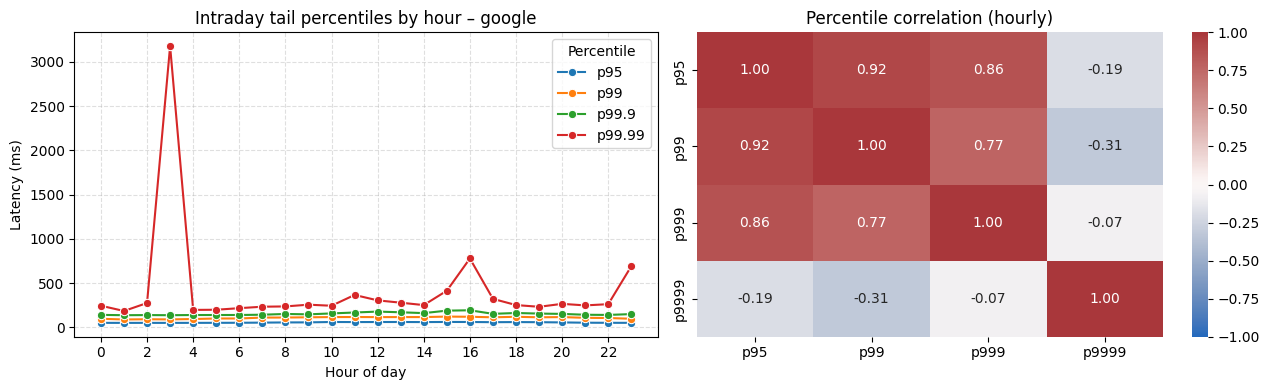

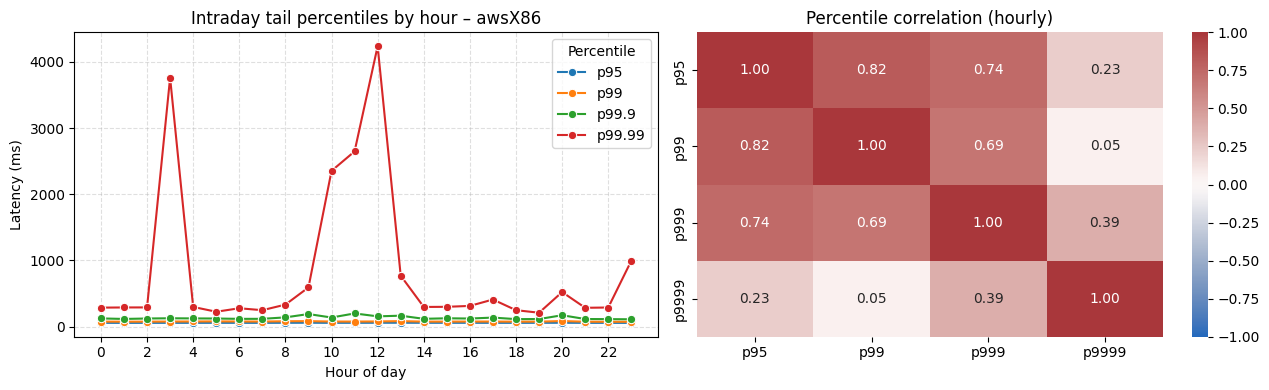

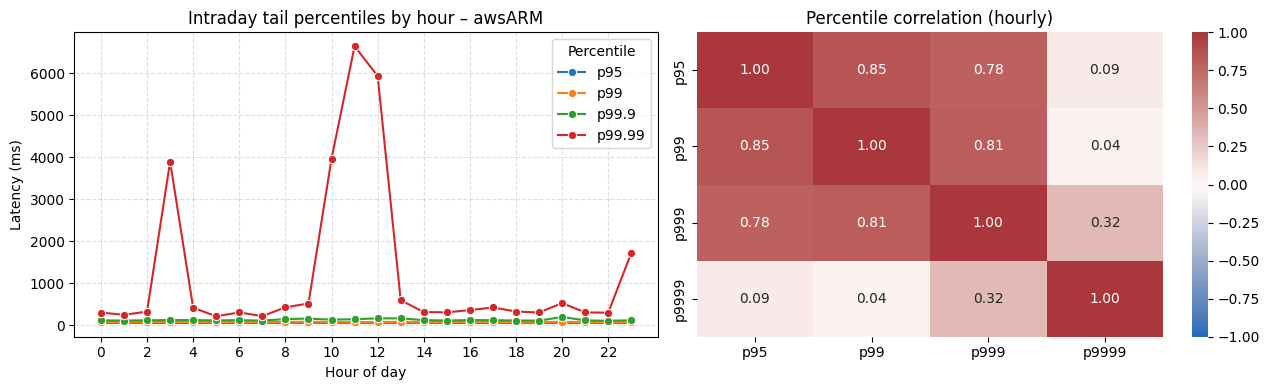

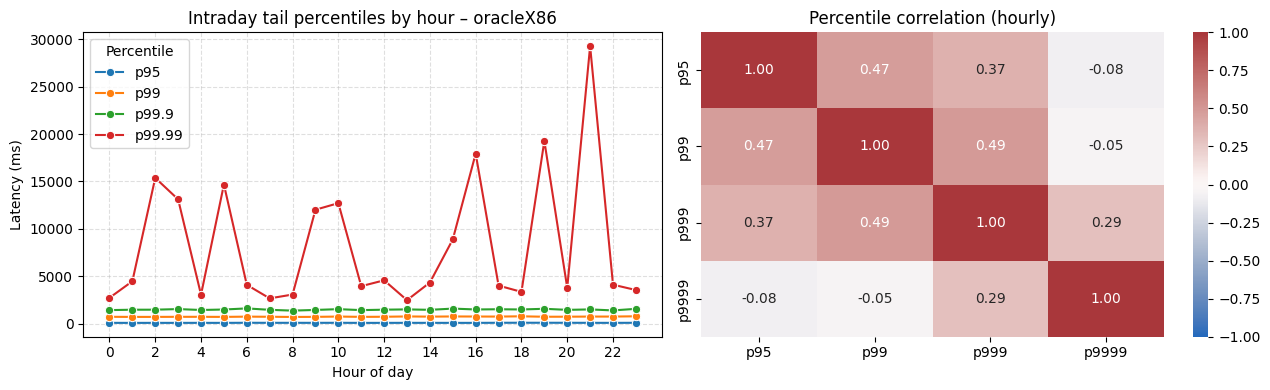

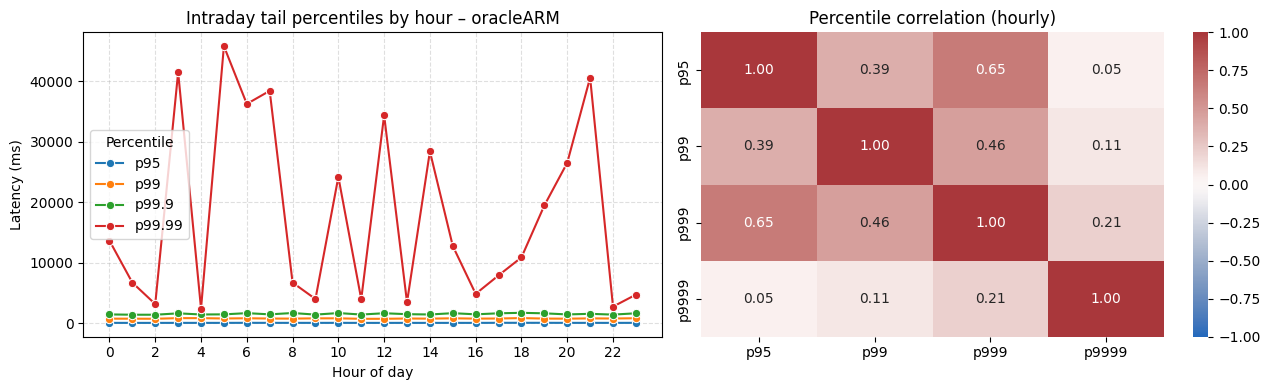

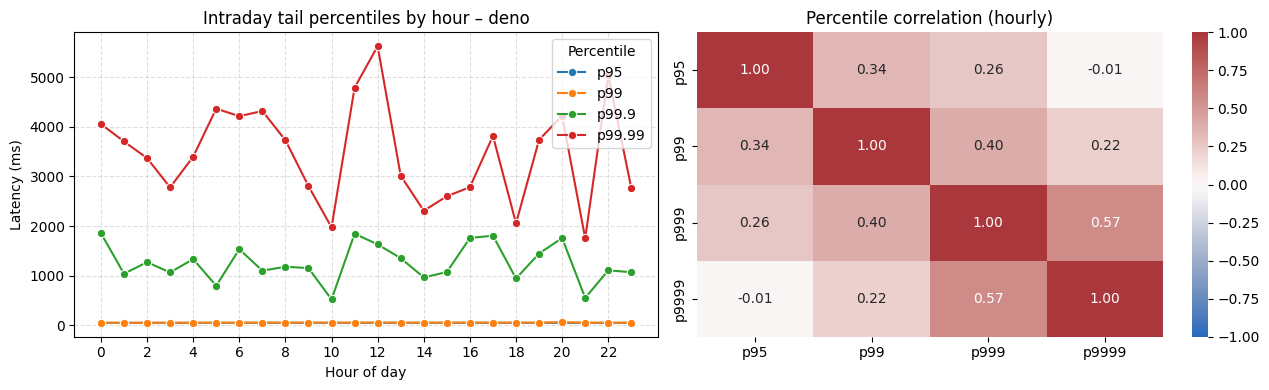

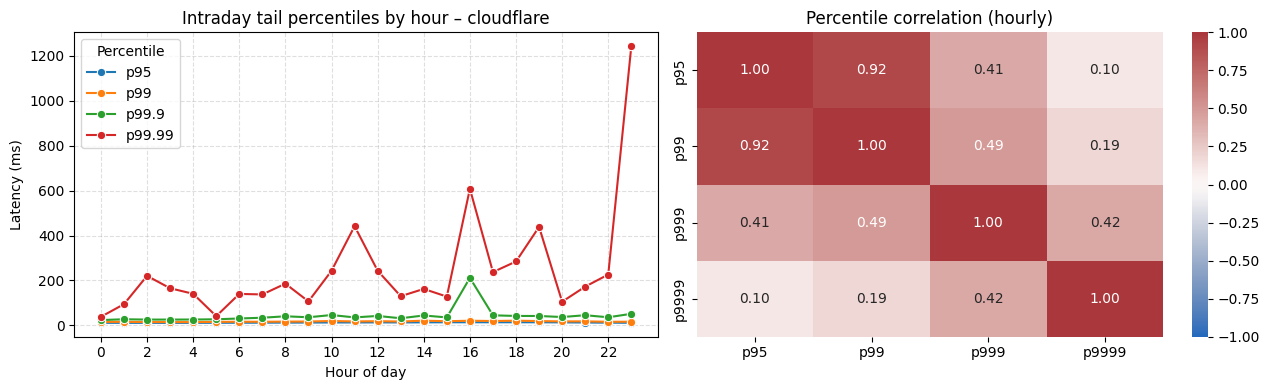

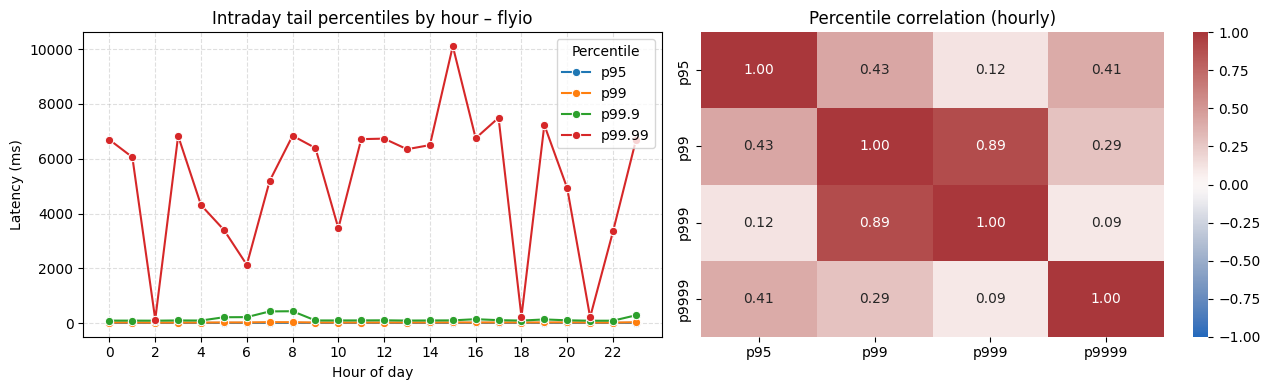

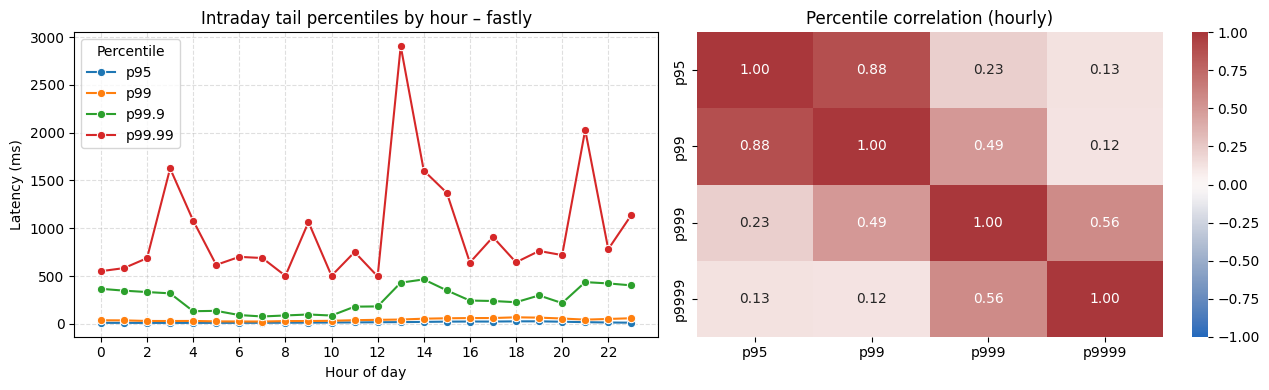

In [ ]:
# Intraday tail-latency patterns by provider (warmstart)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
corr_cols = ["p95", "p99", "p999", "p9999"]

for provider in providers:
    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]

    df_provider = pd.read_sql_query(query, cnx, params=params)
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider["ts"] = pd.to_datetime(
        df_provider["date_time"],
        format="%Y-%m-%dT%H-%M-%S",
        errors="coerce",
    )
    df_provider = df_provider.dropna(subset=["http_req_waiting", "ts"])
    if df_provider.empty:
        continue

    df_provider["hour"] = df_provider["ts"].dt.hour

    hourly_stats = (
        df_provider.groupby("hour", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
            n_samples="size",
        )
        .sort_values("hour")
        .reset_index(drop=True)
    )

    if hourly_stats.empty:
        continue

    fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

    sns.lineplot(data=hourly_stats, x="hour", y="p95", ax=ax_p, marker="o", label="p95")
    sns.lineplot(data=hourly_stats, x="hour", y="p99", ax=ax_p, marker="o", label="p99")
    sns.lineplot(data=hourly_stats, x="hour", y="p999", ax=ax_p, marker="o", label="p99.9")
    sns.lineplot(data=hourly_stats, x="hour", y="p9999", ax=ax_p, marker="o", label="p99.99")

    ax_p.set_title(f"Intraday tail percentiles by hour – {provider}")
    ax_p.set_xlabel("Hour of day")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.set_xticks(range(0, 24, 2))
    ax_p.grid(True, linestyle="--", alpha=0.4)
    ax_p.legend(title="Percentile")

    corr = hourly_stats[corr_cols].corr()
    sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
    ax_corr.set_title("Percentile correlation (hourly)")

    plt.tight_layout()
    plt.show()

    peak_hour = int(hourly_stats.loc[hourly_stats["p99"].idxmax(), "hour"])
    low_hour = int(hourly_stats.loc[hourly_stats["p99"].idxmin(), "hour"])

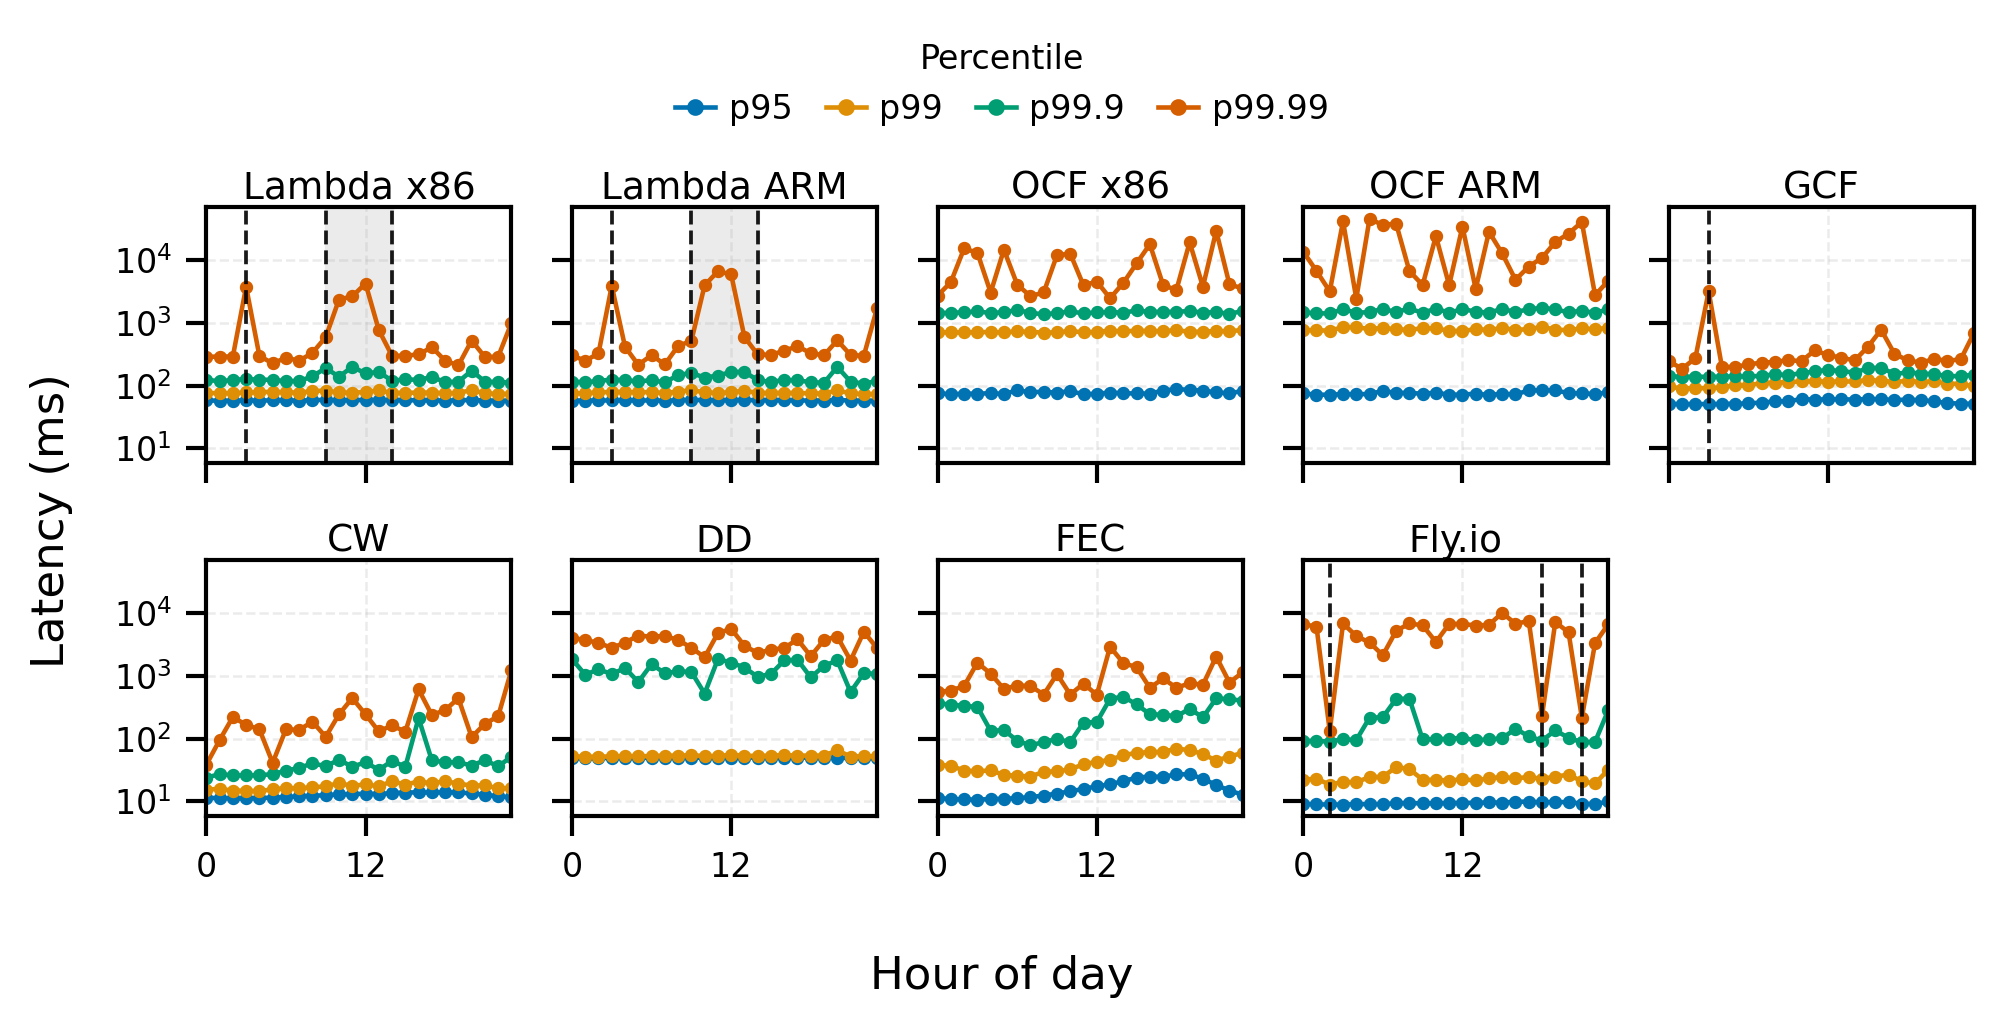

In [6]:
# Combined intraday tail-latency lineplots (warmstart; no heatmaps)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Uses DB connections from Cell 1 if present; falls back to opening them.
if "cnx" not in globals():
    import sqlite3
    cnx = sqlite3.connect("../data.db")
if "cnx_tail" not in globals():
    import sqlite3
    cnx_tail = sqlite3.connect("../data/tail-data_1w.db")

# Provider display names (used in subplot titles)
provider_display = {
    "google": "GCF",
    "awsX86": "Lambda x86",
    "awsARM": "Lambda ARM",
    "oracleX86": "OCF x86",
    "oracleARM": "OCF ARM",
    "cloudflare": "CW",
    "deno": "DD",
    "fastly": "FEC",
    "flyio": "Fly.io",
    "awsEC2": "AWS EC2",
}

# Ordering: keep AWS/Oracle arch variants grouped; total 10 panels.
providers = [
    "awsX86", "awsARM", "oracleX86", "oracleARM", "google",
    "cloudflare", "deno", "fastly", "flyio", "awsEC2",
]
percentiles = [("p95", 0.95), ("p99", 0.99), ("p99.9", 0.999), ("p99.99", 0.9999)]

# --- Annotation maps (edit these to add/remove markers) ---
# Vertical reference lines per provider (single hours).
vlines_by_provider: dict[str, list[float]] = {
    "google": [3],
    "awsX86": [3, 9, 14],
    "awsARM": [3, 9, 14],
    "flyio": [2, 18, 21],
    # Add more as needed, e.g.: "deno": [12],
}

# Shaded ranges per provider: list of (start_hour, end_hour) pairs.
spans_by_provider: dict[str, list[tuple[float, float]]] = {
    "awsX86": [(9, 14)],
    "awsARM": [(9, 14)],
    # Add more as needed, e.g.: "oracleX86": [(2, 4)],
}

def add_vline(provider: str, hour: float) -> None:
    vlines_by_provider.setdefault(provider, []).append(hour)

def add_span(provider: str, start_hour: float, end_hour: float) -> None:
    if start_hour > end_hour:
        start_hour, end_hour = end_hour, start_hour
    spans_by_provider.setdefault(provider, []).append((start_hour, end_hour))

def load_provider_frame(provider: str) -> pd.DataFrame:
    # awsEC2 lives in the tail DB; schema is similar but we do not assume cold_start columns.
    if provider == "awsEC2":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        return pd.read_sql_query(query, cnx_tail, params=[provider])

    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        return pd.read_sql_query(query, cnx, params=[provider])

    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    return pd.read_sql_query(query, cnx, params=[provider])

rows = []
for provider in providers:
    df = load_provider_frame(provider)
    if df.empty:
        continue

    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df["ts"] = pd.to_datetime(df["date_time"], format="%Y-%m-%dT%H-%M-%S", errors="coerce")
    df = df.dropna(subset=["http_req_waiting", "ts"]).copy()
    if df.empty:
        continue

    df["hour"] = df["ts"].dt.hour
    g = df.groupby("hour")["http_req_waiting"]
    hourly = pd.DataFrame({"hour": range(0, 24)}).set_index("hour")

    for label, q in percentiles:
        hourly[label] = g.quantile(q)

    hourly = hourly.reset_index().sort_values("hour")
    hourly["provider"] = provider
    rows.append(hourly)

if not rows:
    print("No data available for the selected providers/filters.")
else:
    all_hourly = pd.concat(rows, ignore_index=True)
    long = all_hourly.melt(
        id_vars=["provider", "hour"],
        value_vars=[p[0] for p in percentiles],
        var_name="percentile",
        value_name="latency_ms",
    ).dropna(subset=["latency_ms"])

    perc_order = [p[0] for p in percentiles]
    perc_palette = dict(zip(perc_order, sns.color_palette("colorblind", n_colors=len(perc_order))))

    # ACM sizing: 2-column width ≈ 6.75in. Explicitly set height for 2×5 panel grid.
    ACM_TWO_COL_W = 6.75
    ACM_TWO_COL_H = 3.25
    rc = {
        "font.size": 9,
        "axes.titlesize": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.title_fontsize": 8,
        "lines.linewidth": 1.1,
    }

    with sns.plotting_context("paper", rc=rc):
        ncols = 5
        nrows = int(np.ceil(len(providers) / ncols))
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(ACM_TWO_COL_W, ACM_TWO_COL_H),
            dpi=300,
            sharex=True,
            sharey=True,
        )
        axes = np.array(axes).reshape(-1)

        for i, provider in enumerate(providers):
            ax = axes[i]
            sub = long[long["provider"] == provider]
            if sub.empty:
                ax.set_axis_off()
                continue

            # Light background spans first (behind everything).
            for x0, x1 in spans_by_provider.get(provider, []):
                ax.axvspan(x0, x1, color="0.92", zorder=0)

            # Quantile curves.
            for perc in perc_order:
                s = sub[sub["percentile"] == perc].sort_values("hour")
                ax.plot(
                    s["hour"],
                    s["latency_ms"],
                    marker="o",
                    markersize=2.2,
                    label=perc,
                    color=perc_palette[perc],
                    zorder=2,
                )

            # Vertical markers (per-provider configurable).
            for x in vlines_by_provider.get(provider, []):
                ax.axvline(x=x, color="black", linestyle="--", linewidth=0.9, alpha=0.9, zorder=3)

            ax.set_title(provider_display.get(provider, provider), pad=2)
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 12))
            ax.grid(True, linestyle="--", alpha=0.25, linewidth=0.6, zorder=1)
            ax.set_yscale("symlog", linthresh=1.0)

        for j in range(len(providers), len(axes)):
            axes[j].set_axis_off()

        fig.supxlabel("Hour of day")
        fig.supylabel("Latency (ms)")

        handles = [
            plt.Line2D([0], [0], color=perc_palette[p], marker="o", linewidth=1.1, markersize=3, label=p)
            for p in perc_order
        ]
        fig.legend(
            handles=handles,
            title="Percentile",
            loc="upper center",
            ncol=4,
            frameon=False,
            bbox_to_anchor=(0.5, 1.02),
            handlelength=1.2,
            columnspacing=1.0,
            handletextpad=0.4,
        )

        # Layout + export
        plt.tight_layout(rect=[0, 0, 1, 0.90])
        fig.savefig("../figures/all-providers-percentiles.pdf", bbox_inches="tight")
        plt.show()

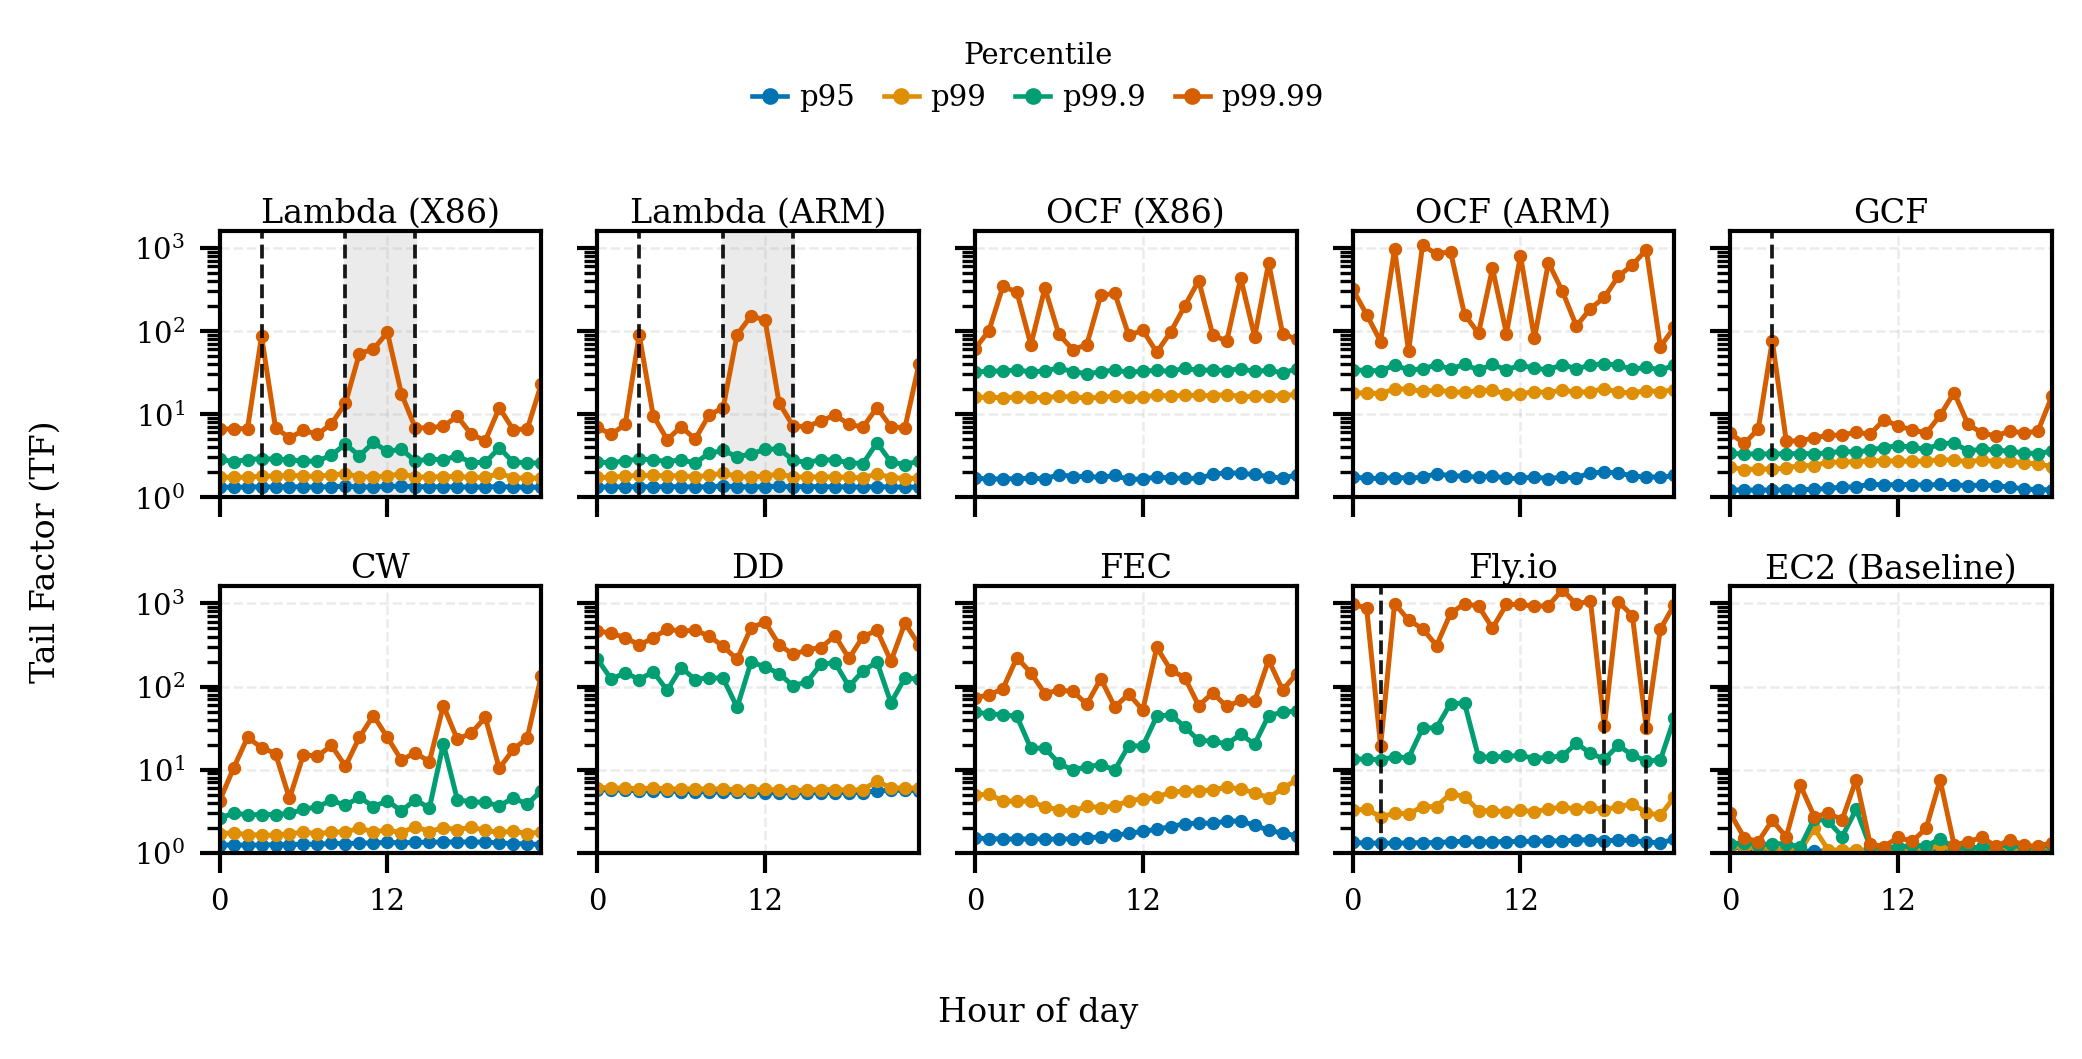

In [3]:
# Combined intraday tail-latency lineplots (warmstart; relative ratio pXX/p50 per provider)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Uses DB connections from Cell 1 if present; falls back to opening them.
if "cnx" not in globals():
    import sqlite3
    cnx = sqlite3.connect("../data.db")

import sqlite3
if "cnx_tail_1w" not in globals() and os.path.exists("../data/tail-data_1w.db"):
    cnx_tail_1w = sqlite3.connect("../data/tail-data_1w.db")

# Back-compat: if an older variable exists, include it as an additional fallback.
cnx_tail_fallback = globals().get("cnx_tail", None)

# Paper-friendly global font update
plt.rcParams.update({
    'font.family': 'serif'
})

# Provider display names strictly matching the mapping from the previous chart
provider_display = {
    "google": "GCF",
    "awsX86": "Lambda (X86)",
    "awsARM": "Lambda (ARM)",
    "oracleX86": "OCF (X86)",
    "oracleARM": "OCF (ARM)",
    "cloudflare": "CW",
    "deno": "DD",
    "fastly": "FEC",
    "flyio": "Fly.io",
    "awsEC2": "EC2 (Baseline)",
}

# Ordering: keep AWS/Oracle arch variants grouped; total 10 panels.
providers = [
    "awsX86", "awsARM", "oracleX86", "oracleARM", "google",
    "cloudflare", "deno", "fastly", "flyio", "awsEC2",
]

# Plot percentiles (numerators). Denominator is hourly p50 (median), so the theoretical minimum is 1.
percentiles = [("p95", 0.95), ("p99", 0.99), ("p99.9", 0.999), ("p99.99", 0.9999)]

# --- Annotation maps (edit these to add/remove markers) ---
# Vertical reference lines per provider (single hours).
vlines_by_provider: dict[str, list[float]] = {
    "google": [3],
    "awsX86": [3, 9, 14],
    "awsARM": [3, 9, 14],
    "flyio": [2, 18, 21],
    # Add more as needed, e.g.: "deno": [12],
}

# Shaded ranges per provider: list of (start_hour, end_hour) pairs.
spans_by_provider: dict[str, list[tuple[float, float]]] = {
    "awsX86": [(9, 14)],
    "awsARM": [(9, 14)],
    # Add more as needed, e.g.: "oracleX86": [(2, 4)],
}

def add_vline(provider: str, hour: float) -> None:
    vlines_by_provider.setdefault(provider, []).append(hour)

def add_span(provider: str, start_hour: float, end_hour: float) -> None:
    if start_hour > end_hour:
        start_hour, end_hour = end_hour, start_hour
    spans_by_provider.setdefault(provider, []).append((start_hour, end_hour))

def _read_tail_frame(cnx_any: sqlite3.Connection, provider: str) -> pd.DataFrame:
    # Baseline.ipynb loads awsEC2 from the tail DB without cold-start filters.
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    return pd.read_sql_query(query, cnx_any, params=[provider])

def _read_tail_frame_any(provider: str) -> pd.DataFrame:
    for conn in [
        globals().get("cnx_tail_1w", None),
        globals().get("cnx_tail_1h", None),
        cnx_tail_fallback,
    ]:
        if conn is None:
            continue
        try:
            df = _read_tail_frame(conn, provider)
        except Exception:
            continue
        if not df.empty:
            return df
    return pd.DataFrame(columns=["date_time", "http_req_waiting"])

def load_provider_frame(provider: str) -> pd.DataFrame:
    # awsEC2 lives in the tail DB; schema is similar but we do not assume cold_start columns.
    if provider == "awsEC2":
        return _read_tail_frame_any(provider)

    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        return pd.read_sql_query(query, cnx, params=[provider])

    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    return pd.read_sql_query(query, cnx, params=[provider])

rows = []
for provider in providers:
    df = load_provider_frame(provider)
    if df.empty:
        continue

    df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
    df["ts"] = pd.to_datetime(df["date_time"], format="%Y-%m-%dT%H-%M-%S", errors="coerce")
    df = df.dropna(subset=["http_req_waiting", "ts"]).copy()

    # Ratio requires a positive denominator.
    df = df[df["http_req_waiting"] > 0].copy()
    if df.empty:
        continue

    df["hour"] = df["ts"].dt.hour
    g = df.groupby("hour")["http_req_waiting"]

    hourly = pd.DataFrame({"hour": range(0, 24)}).set_index("hour")

    # Denominator: hourly median (p50).
    hourly["p50"] = g.quantile(0.50)
    hourly.loc[hourly["p50"] <= 0, "p50"] = np.nan

    # Numerators: hourly tail percentiles.
    for label, q in percentiles:
        hourly[label] = g.quantile(q)

    hourly = hourly.reset_index().sort_values("hour")

    # Ratio relative to hourly p50: pXX / p50. 
    # This is ALREADY relative! Theoretical minimum is 1.0 (meaning tail == median)
    for label, _q in percentiles:
        hourly[label] = hourly[label] / hourly["p50"]

    hourly["provider"] = provider
    rows.append(hourly[["provider", "hour"] + [p[0] for p in percentiles]])

if not rows:
    print("No data available for the selected providers/filters.")
else:
    all_hourly = pd.concat(rows, ignore_index=True)
    long = all_hourly.melt(
        id_vars=["provider", "hour"],
        value_vars=[p[0] for p in percentiles],
        var_name="percentile",
        value_name="ratio_pxx_p50",
    ).dropna(subset=["ratio_pxx_p50"])

    perc_order = [p[0] for p in percentiles]
    perc_palette = dict(zip(perc_order, sns.color_palette("colorblind", n_colors=len(perc_order))))

    # Global y-limit (shared across subplots) to avoid clipping.
    ymax = float(np.nanmax(long["ratio_pxx_p50"].to_numpy(dtype=float)))
    if not np.isfinite(ymax) or ymax < 1:
        ymax = 1.0
    ymax = max(1.1, ymax * 1.10)

    # ACM sizing: Standard 2-column full width is 7.0 inches
    ACM_TWO_COL_W = 7.0
    ACM_TWO_COL_H = 3.25
    
    # 8pt is standard for Middleware body, 7pt for legends/ticks
    rc = {
        "font.family": "serif",
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "legend.title_fontsize": 7,
        "lines.linewidth": 1.2,
    }

    with sns.plotting_context("paper", rc=rc):
        ncols = 5
        nrows = int(np.ceil(len(providers) / ncols))
        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(ACM_TWO_COL_W, ACM_TWO_COL_H),
            dpi=300,
            sharex=True,
            sharey=True,
        )
        axes = np.array(axes).reshape(-1)

        for i, provider in enumerate(providers):
            ax = axes[i]
            sub = long[long["provider"] == provider]
            if sub.empty:
                ax.set_axis_off()
                continue

            # Light background spans first (behind everything).
            for x0, x1 in spans_by_provider.get(provider, []):
                ax.axvspan(x0, x1, color="0.92", zorder=0)

            # Quantile curves (ratio pXX/p50).
            for perc in perc_order:
                s = sub[sub["percentile"] == perc].sort_values("hour")
                ax.plot(
                    s["hour"],
                    s["ratio_pxx_p50"],
                    marker="o",
                    markersize=2.2,
                    label=perc,
                    color=perc_palette[perc],
                    zorder=2,
                )

            # Vertical markers (per-provider configurable).
            for x in vlines_by_provider.get(provider, []):
                ax.axvline(x=x, color="black", linestyle="--", linewidth=0.9, alpha=0.9, zorder=3)

            ax.set_title(provider_display.get(provider, provider), pad=2)
            ax.set_xlim(0, 23)
            ax.set_xticks(range(0, 24, 12))
            
            # Explicitly turn off minor ticks (subticks) generated by the log scale
            ax.minorticks_off()
            
            ax.grid(True, linestyle="--", alpha=0.25, linewidth=0.6, zorder=1)
            ax.set_yscale("log", base=10)

        # Apply shared y-limits once (prevents subplot-to-subplot autoscale clipping).
        axes[0].set_ylim(bottom=1, top=ymax)

        for j in range(len(providers), len(axes)):
            axes[j].set_axis_off()

        fig.supxlabel("Hour of day", fontsize=8)
        fig.supylabel("Tail Factor (TF)", fontsize=8)

        handles = [
            plt.Line2D([0], [0], color=perc_palette[p], marker="o", linewidth=1.1, markersize=3, label=p)
            for p in perc_order
        ]
        
        # Adjust bbox_to_anchor specifically to clear the plots without excessive whitespace
        fig.legend(
            handles=handles,
            title="Percentile",
            loc="upper center",
            ncol=4,
            frameon=False,
            bbox_to_anchor=(0.5, 1.05),
            handlelength=1.2,
            columnspacing=1.0,
            handletextpad=0.4,
        )

        # Layout + export
        plt.tight_layout(rect=[0.02, 0.02, 1, 0.90])
        fig.savefig("../figures/all-providers-percentiles-relative-median.pdf", bbox_inches="tight")
        plt.show()

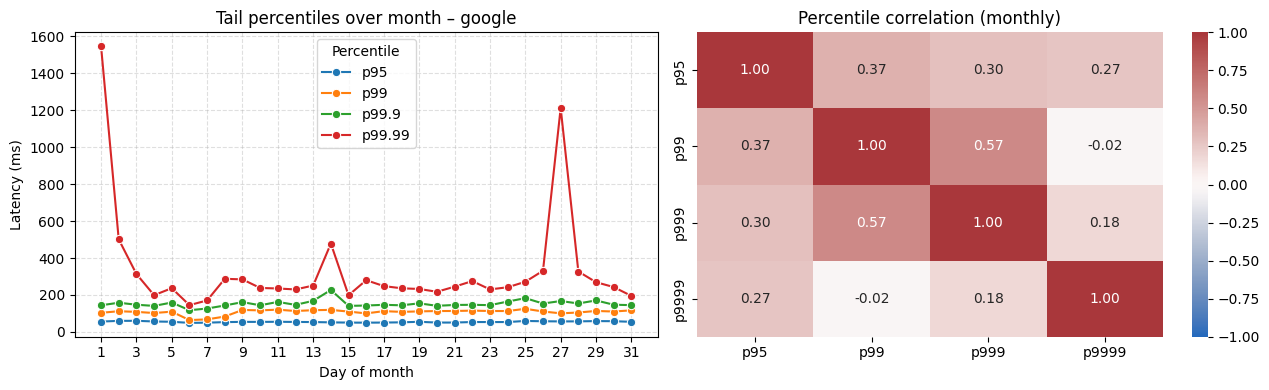

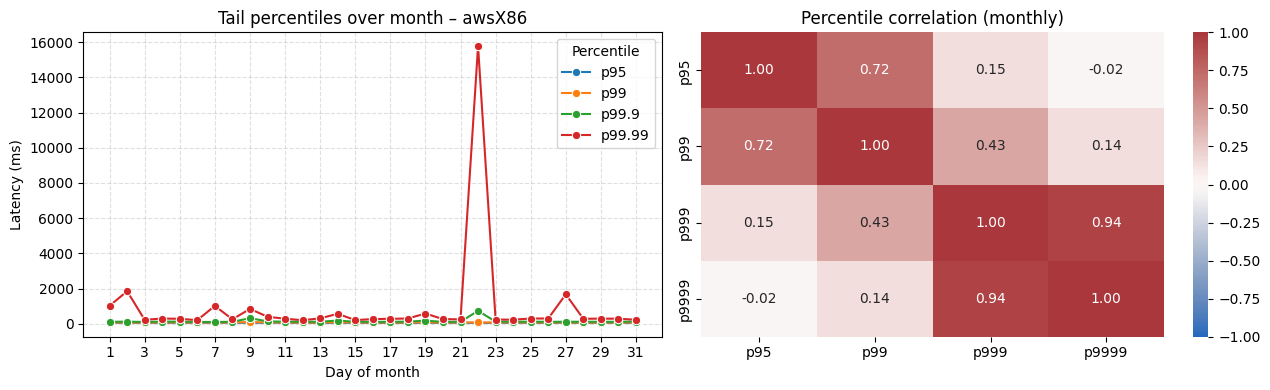

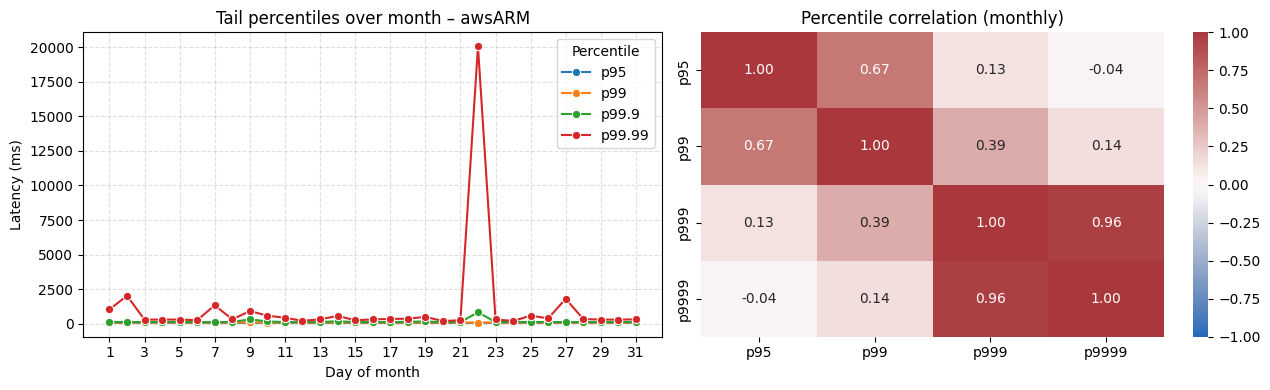

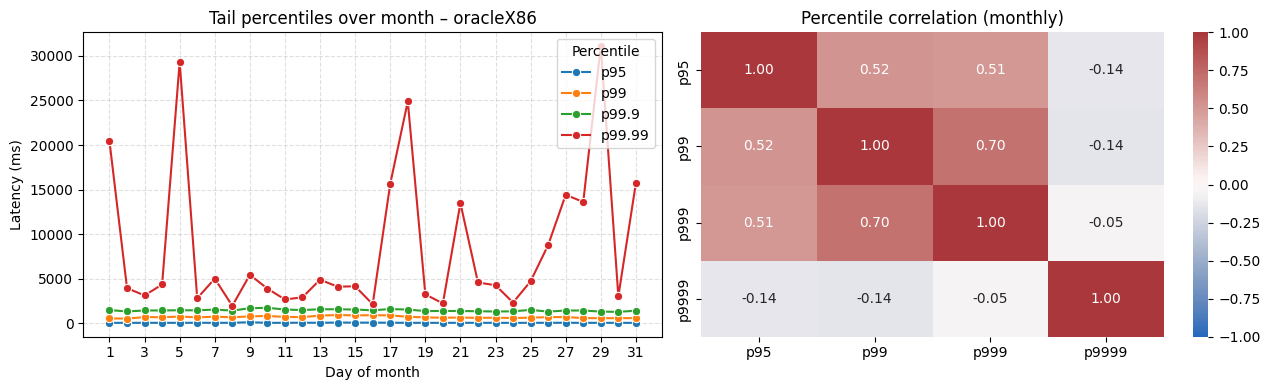

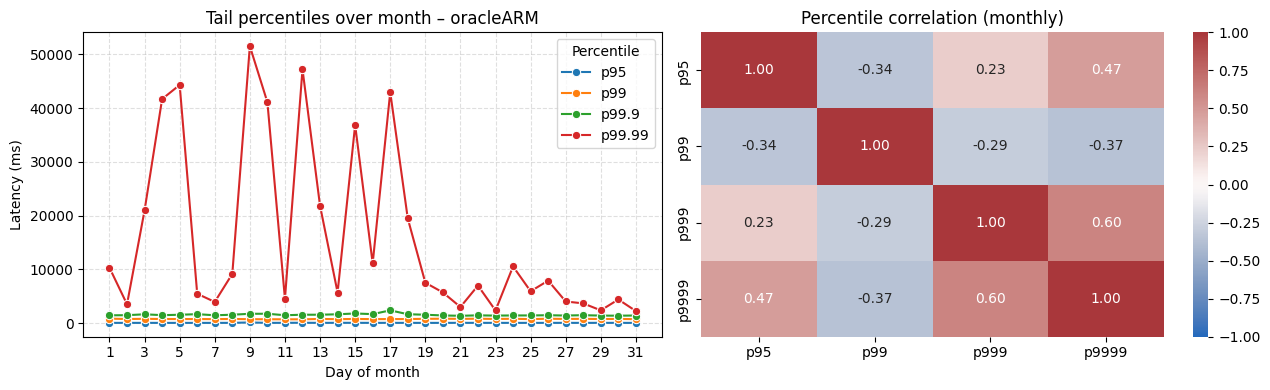

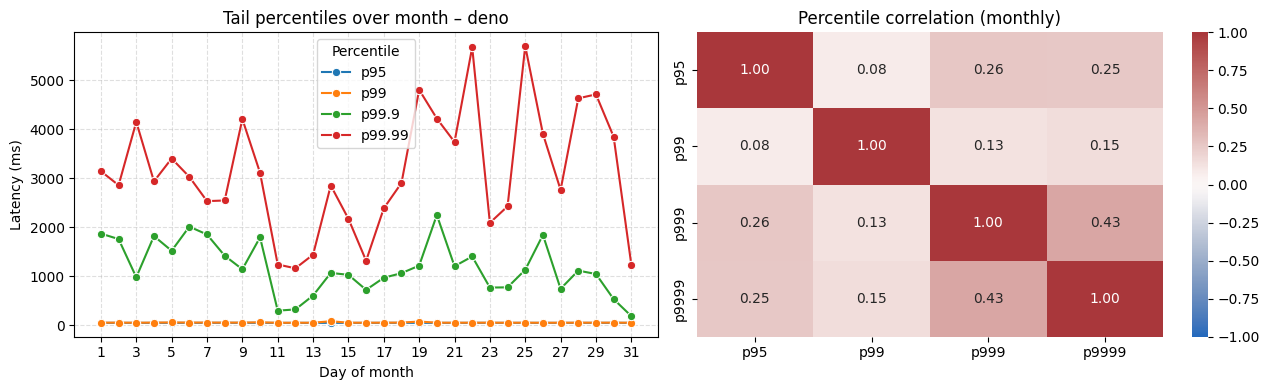

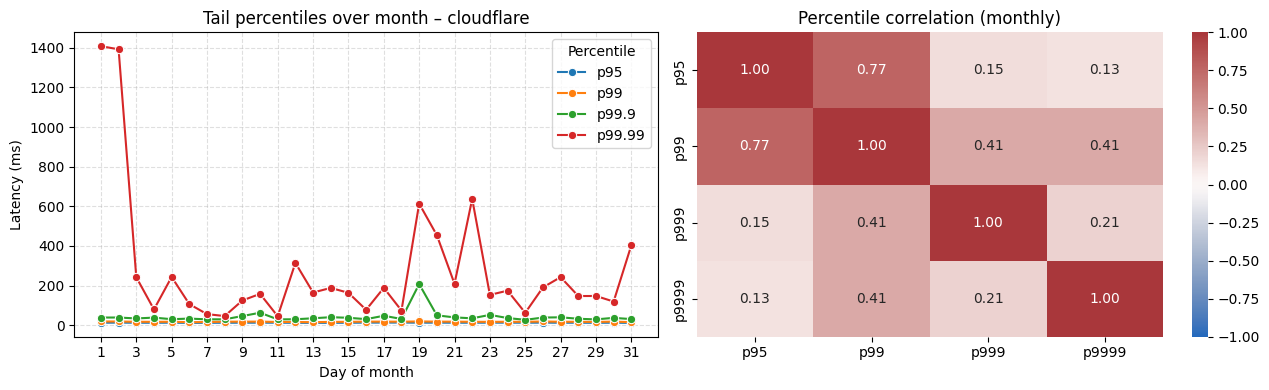

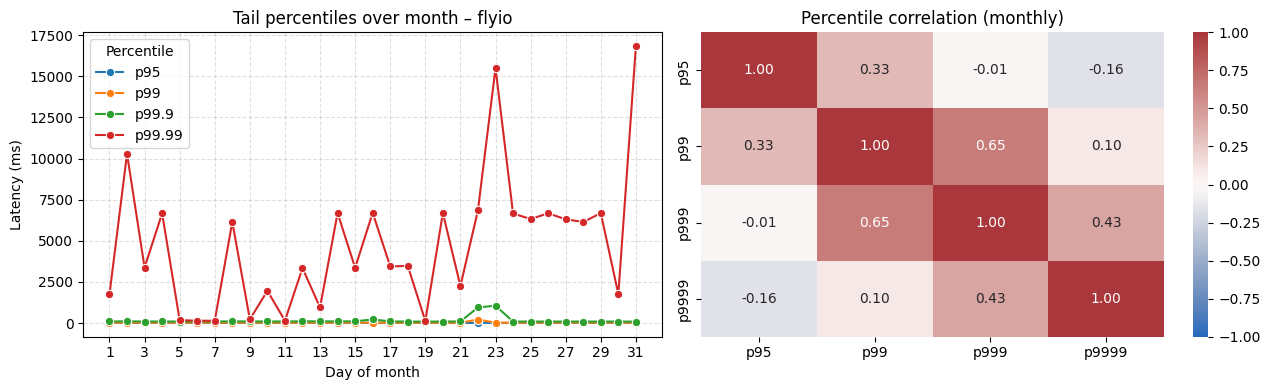

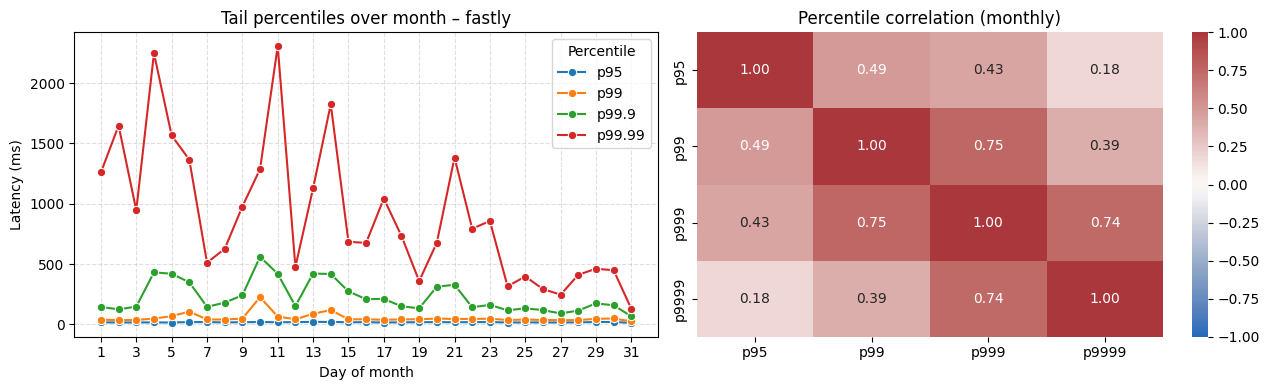

In [ ]:
# Monthly tail-latency patterns by provider (day of month, warmstart)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
corr_cols = ["p95", "p99", "p999", "p9999"]

for provider in providers:
    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
        params = [provider]
    else:
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """
        params = [provider]

    df_provider = pd.read_sql_query(query, cnx, params=params)
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider["ts"] = pd.to_datetime(
        df_provider["date_time"],
        format="%Y-%m-%dT%H-%M-%S",
        errors="coerce",
    )
    df_provider = df_provider.dropna(subset=["http_req_waiting", "ts"])
    if df_provider.empty:
        continue

    df_provider["day_of_month"] = df_provider["ts"].dt.day

    monthly_stats = (
        df_provider.groupby("day_of_month", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
            n_samples="size",
        )
        .sort_values("day_of_month")
        .reset_index(drop=True)
    )

    if monthly_stats.empty:
        continue

    fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

    sns.lineplot(data=monthly_stats, x="day_of_month", y="p95", ax=ax_p, marker="o", label="p95")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p99", ax=ax_p, marker="o", label="p99")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p999", ax=ax_p, marker="o", label="p99.9")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p9999", ax=ax_p, marker="o", label="p99.99")

    ax_p.set_title(f"Tail percentiles over month – {provider}")
    ax_p.set_xlabel("Day of month")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.set_xticks(range(1, 32, 2))
    ax_p.grid(True, linestyle="--", alpha=0.4)
    ax_p.legend(title="Percentile")

    corr = monthly_stats[corr_cols].corr()
    sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
    ax_corr.set_title("Percentile correlation (monthly)")

    plt.tight_layout()
    plt.show()

    peak_day = int(monthly_stats.loc[monthly_stats["p99"].idxmax(), "day_of_month"])
    low_day = int(monthly_stats.loc[monthly_stats["p99"].idxmin(), "day_of_month"])

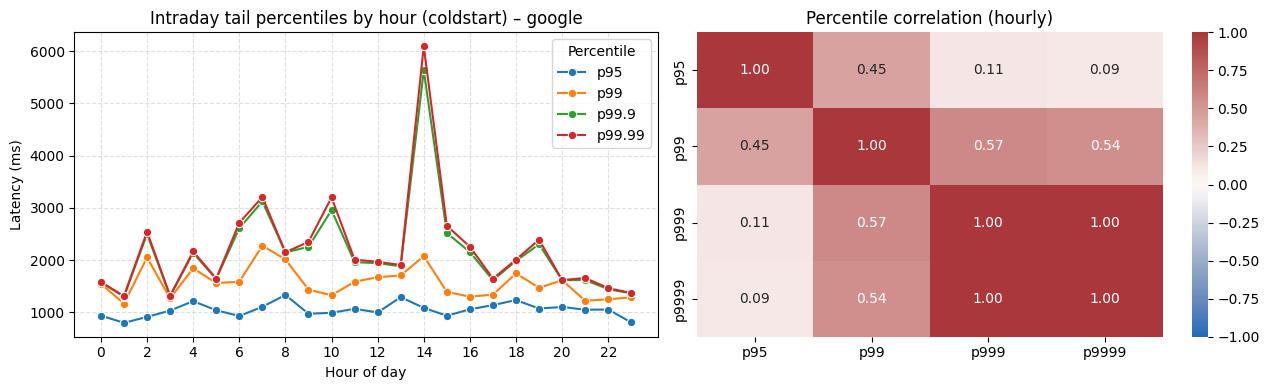

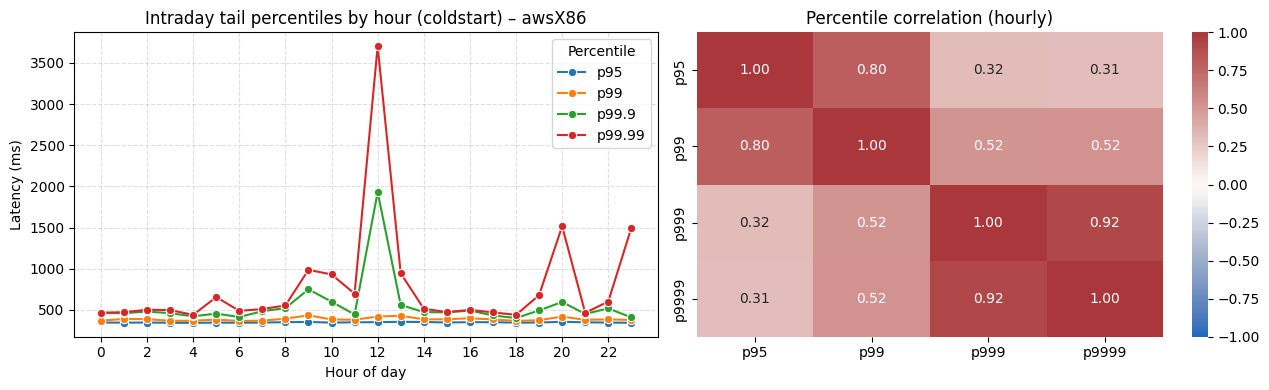

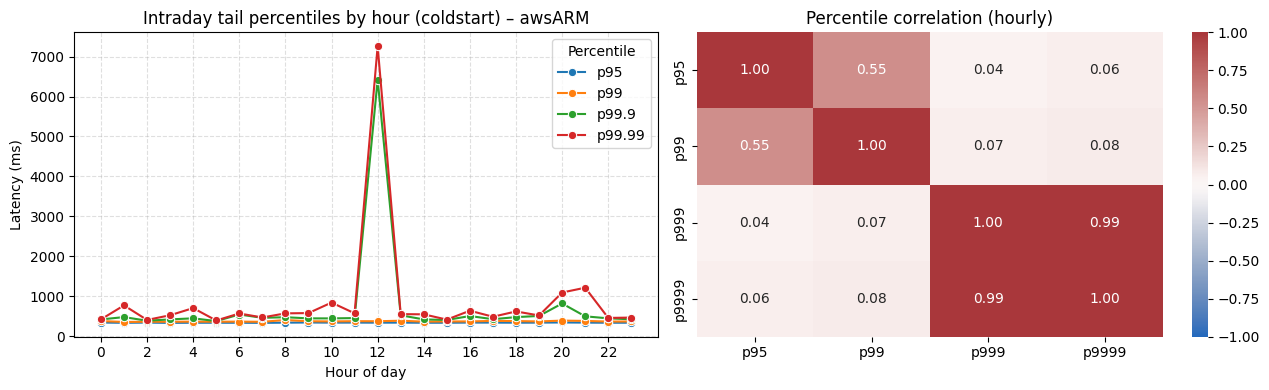

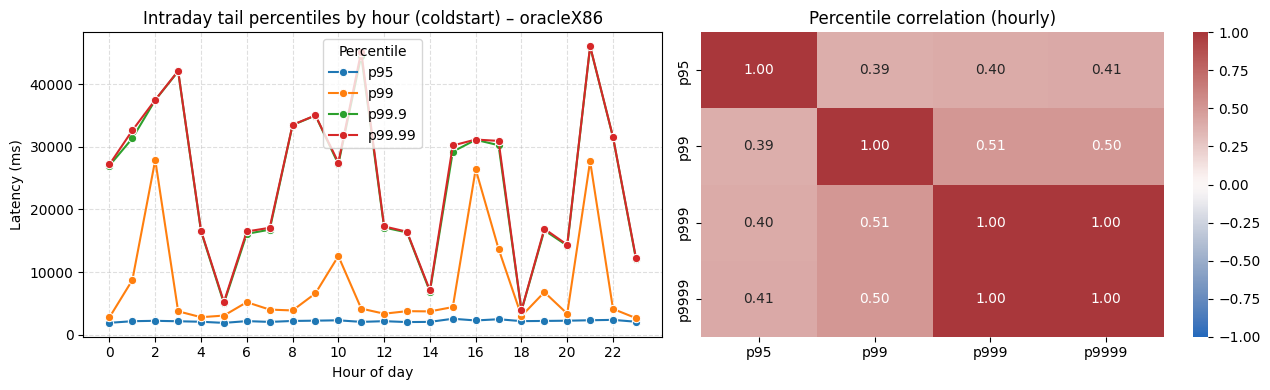

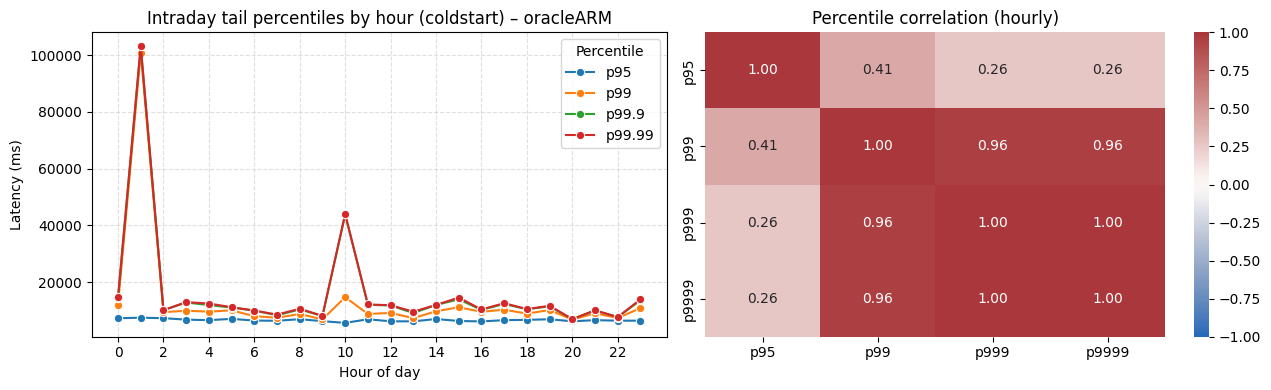

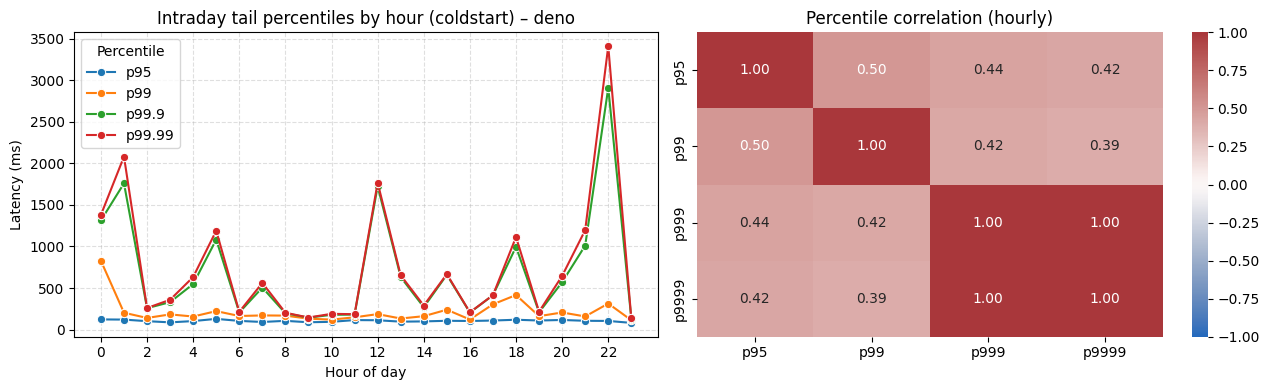

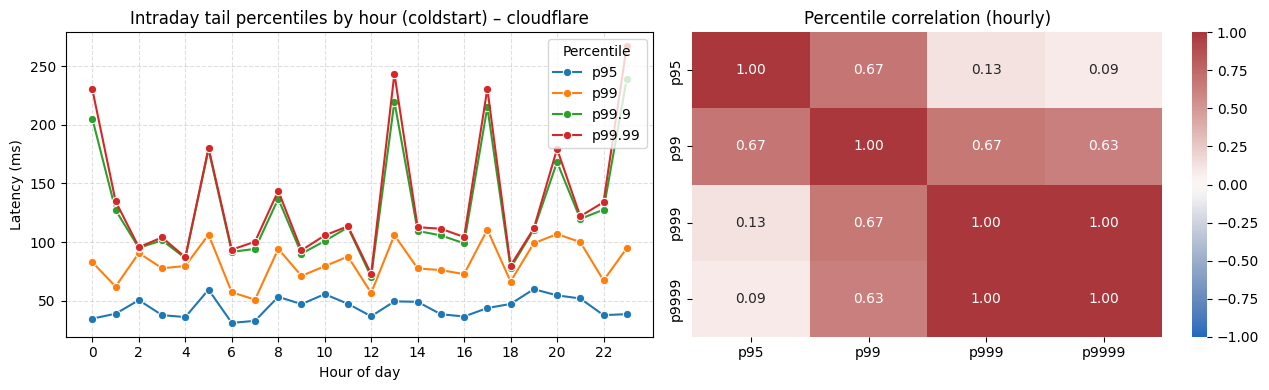

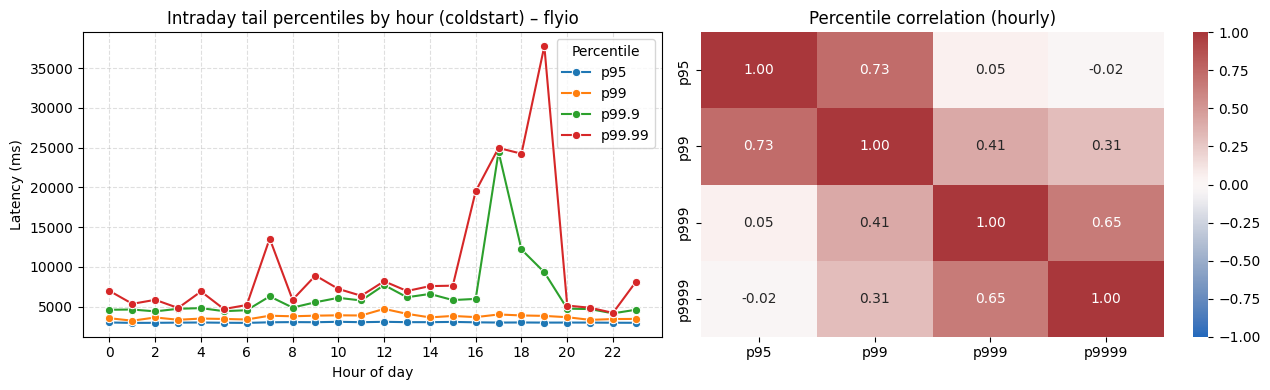

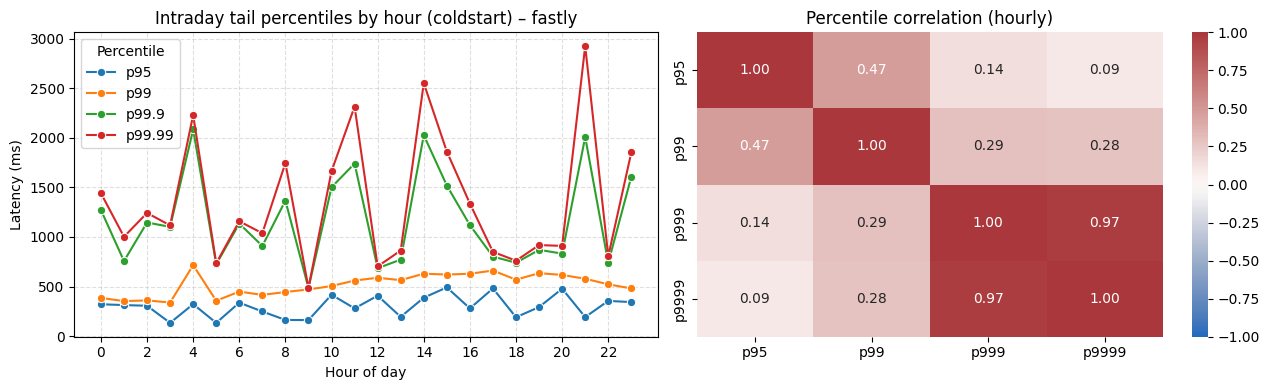

In [ ]:
# Intraday tail-latency patterns by provider (coldstart)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
corr_cols = ["p95", "p99", "p999", "p9999"]

for provider in providers:
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

    df_provider = pd.read_sql_query(query, cnx, params=params)
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider["ts"] = pd.to_datetime(
        df_provider["date_time"],
        format="%Y-%m-%dT%H-%M-%S",
        errors="coerce",
    )
    df_provider = df_provider.dropna(subset=["http_req_waiting", "ts"])
    if df_provider.empty:
        continue

    df_provider["hour"] = df_provider["ts"].dt.hour

    hourly_stats = (
        df_provider.groupby("hour", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
            n_samples="size",
        )
        .sort_values("hour")
        .reset_index(drop=True)
    )

    if hourly_stats.empty:
        continue

    fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

    sns.lineplot(data=hourly_stats, x="hour", y="p95", ax=ax_p, marker="o", label="p95")
    sns.lineplot(data=hourly_stats, x="hour", y="p99", ax=ax_p, marker="o", label="p99")
    sns.lineplot(data=hourly_stats, x="hour", y="p999", ax=ax_p, marker="o", label="p99.9")
    sns.lineplot(data=hourly_stats, x="hour", y="p9999", ax=ax_p, marker="o", label="p99.99")

    ax_p.set_title(f"Intraday tail percentiles by hour (coldstart) – {provider}")
    ax_p.set_xlabel("Hour of day")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.set_xticks(range(0, 24, 2))
    ax_p.grid(True, linestyle="--", alpha=0.4)
    ax_p.legend(title="Percentile")

    corr = hourly_stats[corr_cols].corr()
    sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
    ax_corr.set_title("Percentile correlation (hourly)")

    plt.tight_layout()
    plt.show()

    peak_hour = int(hourly_stats.loc[hourly_stats["p99"].idxmax(), "hour"])
    low_hour = int(hourly_stats.loc[hourly_stats["p99"].idxmin(), "hour"])

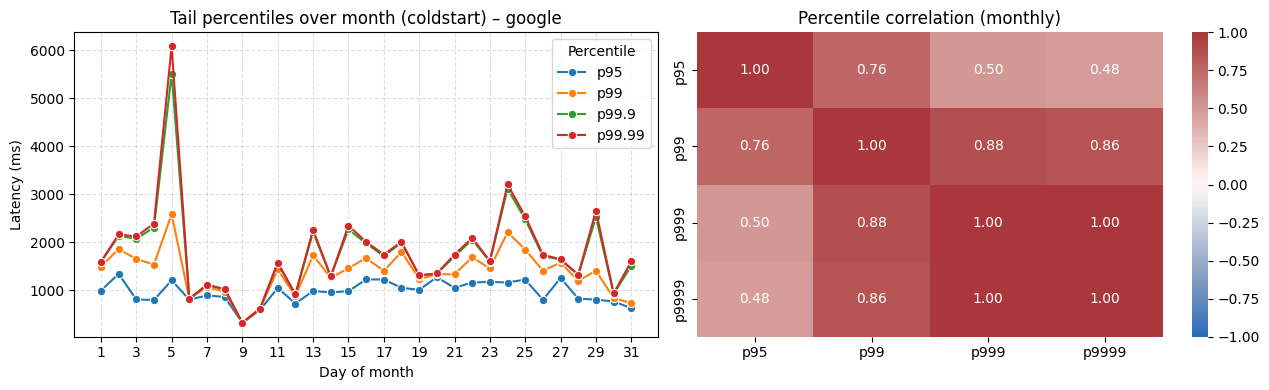

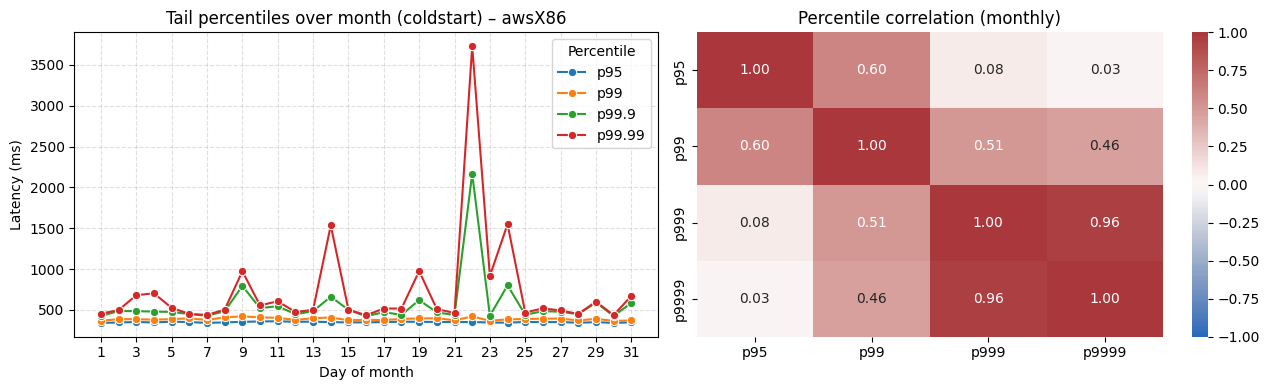

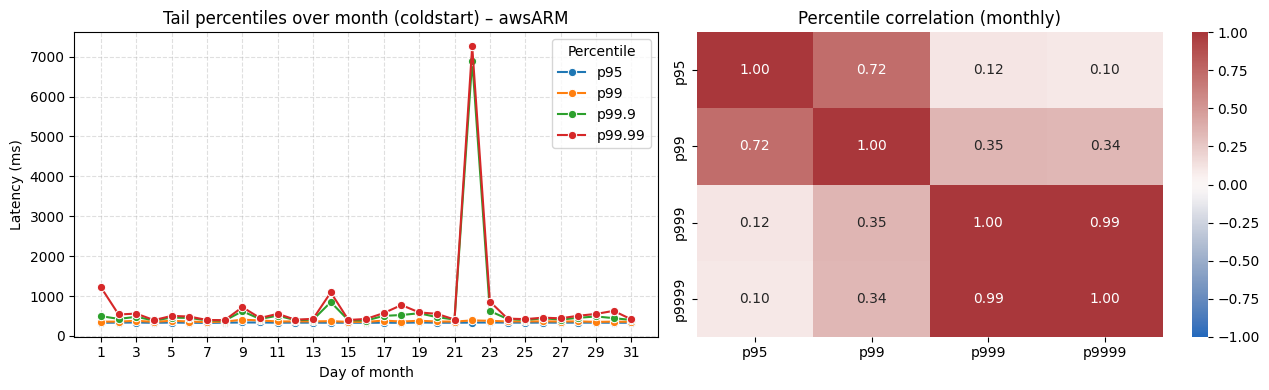

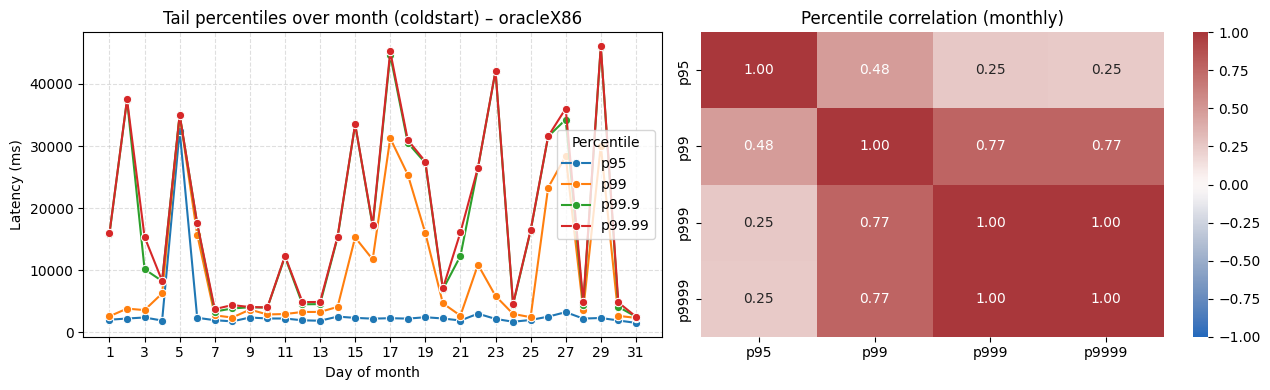

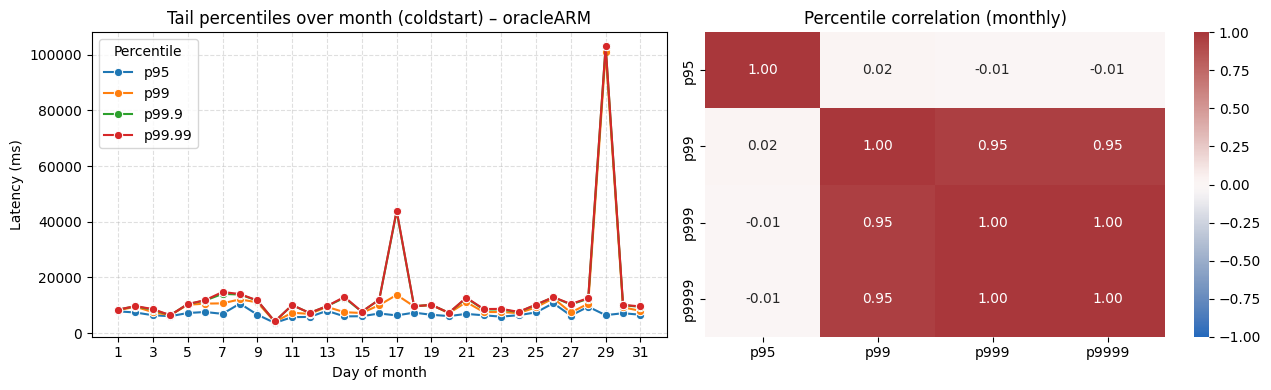

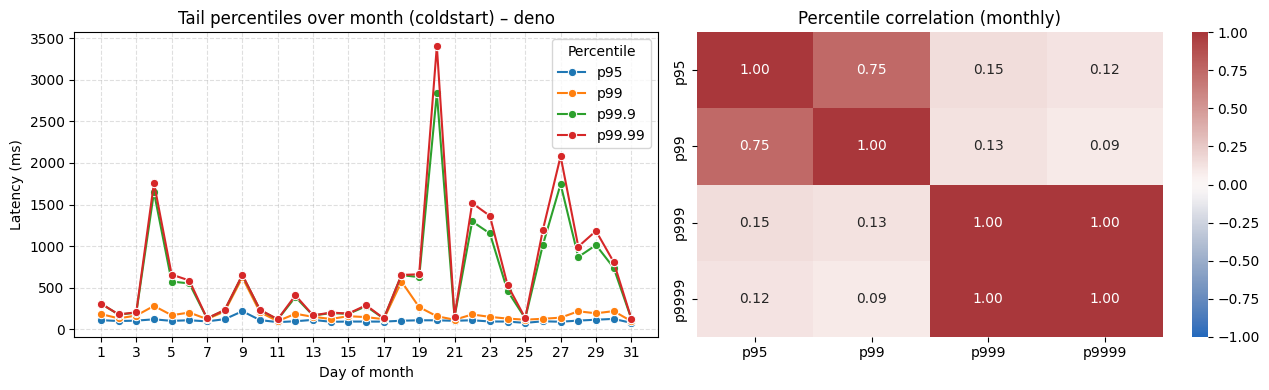

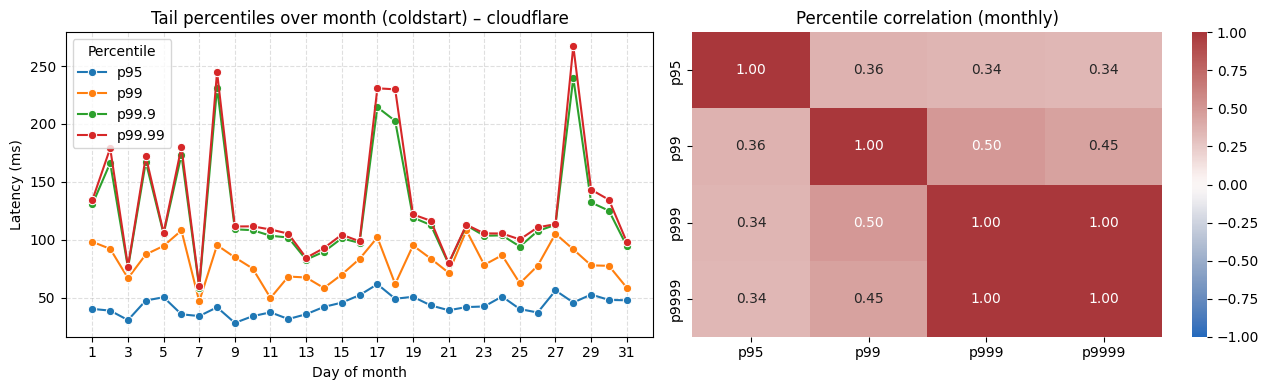

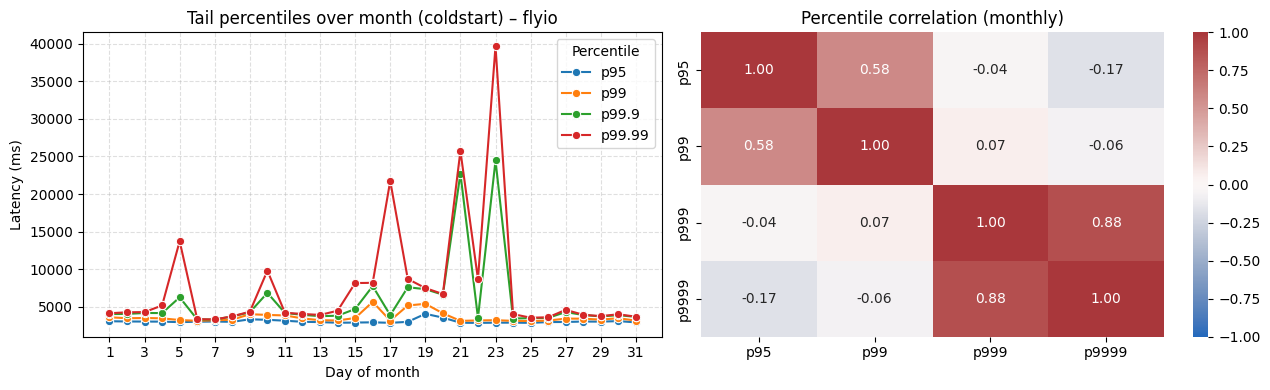

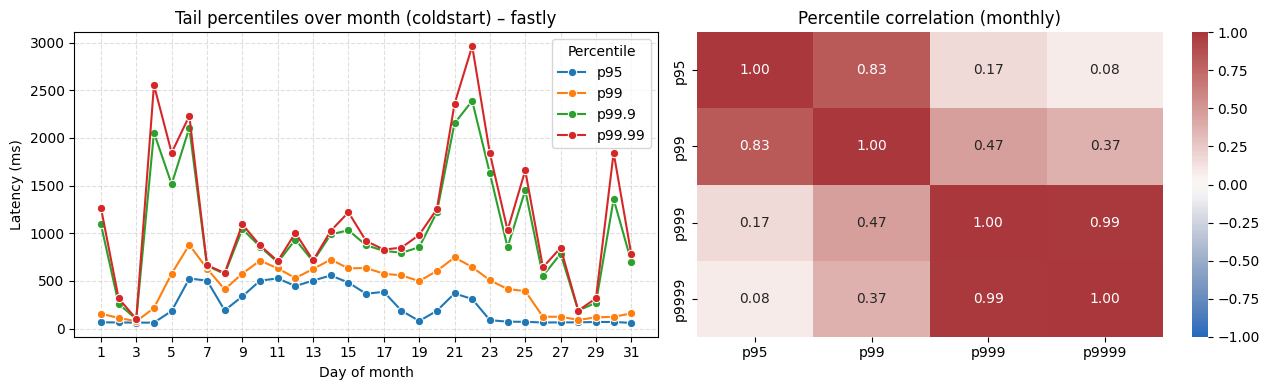

In [ ]:
# Monthly tail-latency patterns by provider (day of month, coldstart)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
corr_cols = ["p95", "p99", "p999", "p9999"]

for provider in providers:
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

    df_provider = pd.read_sql_query(query, cnx, params=params)
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider["ts"] = pd.to_datetime(
        df_provider["date_time"],
        format="%Y-%m-%dT%H-%M-%S",
        errors="coerce",
    )
    df_provider = df_provider.dropna(subset=["http_req_waiting", "ts"])
    if df_provider.empty:
        continue

    df_provider["day_of_month"] = df_provider["ts"].dt.day

    monthly_stats = (
        df_provider.groupby("day_of_month", as_index=False)["http_req_waiting"]
        .agg(
            p95=lambda s: s.quantile(0.95),
            p99=lambda s: s.quantile(0.99),
            p999=lambda s: s.quantile(0.999),
            p9999=lambda s: s.quantile(0.9999),
            n_samples="size",
        )
        .sort_values("day_of_month")
        .reset_index(drop=True)
    )

    if monthly_stats.empty:
        continue

    fig, (ax_p, ax_corr) = plt.subplots(1, 2, figsize=(13, 4), sharey=False)

    sns.lineplot(data=monthly_stats, x="day_of_month", y="p95", ax=ax_p, marker="o", label="p95")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p99", ax=ax_p, marker="o", label="p99")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p999", ax=ax_p, marker="o", label="p99.9")
    sns.lineplot(data=monthly_stats, x="day_of_month", y="p9999", ax=ax_p, marker="o", label="p99.99")

    ax_p.set_title(f"Tail percentiles over month (coldstart) – {provider}")
    ax_p.set_xlabel("Day of month")
    ax_p.set_ylabel("Latency (ms)")
    ax_p.set_xticks(range(1, 32, 2))
    ax_p.grid(True, linestyle="--", alpha=0.4)
    ax_p.legend(title="Percentile")

    corr = monthly_stats[corr_cols].corr()
    sns.heatmap(corr, ax=ax_corr, vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", cbar=True)
    ax_corr.set_title("Percentile correlation (monthly)")

    plt.tight_layout()
    plt.show()

    peak_day = int(monthly_stats.loc[monthly_stats["p99"].idxmax(), "day_of_month"])
    low_day = int(monthly_stats.loc[monthly_stats["p99"].idxmin(), "day_of_month"])

<notebook cell>:184: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
<site-packages>:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


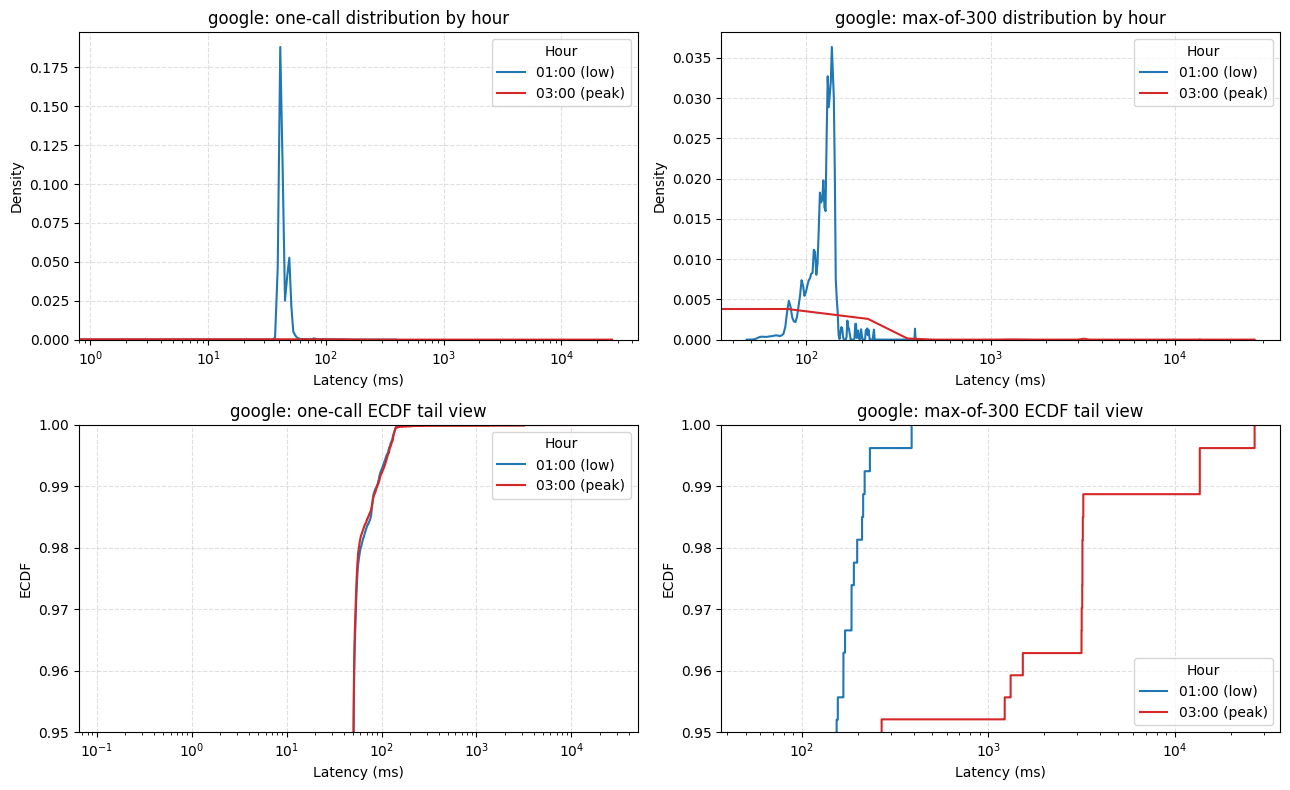

Hour-level p99.99 isolation summary


,provider,experiment,hour,n_one_call,n_max500_samples,one_call_p99.99,max500_p99.99,p99.99_inflation_max500_vs_one_call
0,google,warmstart,01:00,79326,10000000,185.093417,388.922947,2.101225
1,google,warmstart,03:00,79265,10000000,3177.710264,26859.418854,8.452444


Unique-value and p95 count diagnostics


,hour,n_one_call_total,one_call_unique_all,one_call_unique_tail_ge_p95,one_call_p95_threshold,one_call_count_le_p95_actual,one_call_count_gt_p95_actual,one_call_count_le_p95_theoretical,one_call_count_gt_p95_theoretical,max500_unique_all,max500_unique_tail_ge_p95,max500_tail_sample_count_ge_p95
0,01:00,79326,78873,3967,50.766429,75359,3967,75360,3966,2909,14,515658
1,03:00,79265,78792,3964,50.748395,75301,3964,75302,3963,2876,14,514975


In [2]:
# Isolate p99.99 impact for Google: 01:00 (low) vs 03:00 (peak)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from IPython.display import display

if "cnx" not in globals():
    cnx = sqlite3.connect("../data.db")

provider = "google"
experiment = "warmstart"  # change to "coldstart" if needed
hour_low = 1   # 01:00
hour_peak = 3  # 03:00
hours_of_interest = [hour_low, hour_peak]

n_calls = 300
n_samples = 10000000
rng = np.random.default_rng(42)

if experiment == "warmstart" and provider != "fastly":
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
          AND cold_starts = 0
    """
    params = [provider]
elif experiment == "warmstart" and provider == "fastly":
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'warmstart'
    """
    params = [provider]
else:
    query = """
        SELECT date_time, http_req_waiting
        FROM data
        WHERE provider = ?
          AND experiment = 'coldstart'
          AND cold_starts = 1
    """
    params = [provider]

df = pd.read_sql_query(query, cnx, params=params)
df["http_req_waiting"] = pd.to_numeric(df["http_req_waiting"], errors="coerce")
df["ts"] = pd.to_datetime(
    df["date_time"],
    format="%Y-%m-%dT%H-%M-%S",
    errors="coerce",
)
df = df.dropna(subset=["http_req_waiting", "ts"]).copy()
df = df[df["http_req_waiting"] > 0].copy()

if df.empty:
    print(f"No valid latency data for provider {provider} ({experiment}).")
else:
    df["hour"] = df["ts"].dt.hour
    df = df[df["hour"].isin(hours_of_interest)]

    if df.empty:
        print("No rows found for the selected hours.")
    else:
        hour_labels = {
            hour_low: f"{hour_low:02d}:00 (low)",
            hour_peak: f"{hour_peak:02d}:00 (peak)",
        }

        one_call_samples = {}
        max500_samples = {}
        summary_rows = []
        diagnostics_rows = []

        for hour in hours_of_interest:
            lat = df.loc[df["hour"] == hour, "http_req_waiting"].to_numpy()
            if lat.size == 0:
                print(f"No data for hour {hour:02d}:00")
                continue

            one_call_samples[hour] = lat
            draws = rng.choice(lat, size=(n_samples, n_calls), replace=True)
            max_of_n = draws.max(axis=1)
            max500_samples[hour] = max_of_n

            p95_one = float(np.quantile(lat, 0.95))
            p9999_one = float(np.quantile(lat, 0.9999))
            p9999_max500 = float(np.quantile(max_of_n, 0.9999))

            n_total = int(lat.size)
            n_le_p95_actual = int((lat <= p95_one).sum())
            n_gt_p95_actual = int((lat > p95_one).sum())
            n_le_p95_theoretical = int(round(0.95 * n_total))
            n_gt_p95_theoretical = n_total - n_le_p95_theoretical

            max500_p95 = float(np.quantile(max_of_n, 0.95))

            diagnostics_rows.append(
                {
                    "hour": f"{hour:02d}:00",
                    "n_one_call_total": n_total,
                    "one_call_unique_all": int(np.unique(lat).size),
                    "one_call_unique_tail_ge_p95": int(np.unique(lat[lat >= p95_one]).size),
                    "one_call_p95_threshold": p95_one,
                    "one_call_count_le_p95_actual": n_le_p95_actual,
                    "one_call_count_gt_p95_actual": n_gt_p95_actual,
                    "one_call_count_le_p95_theoretical": n_le_p95_theoretical,
                    "one_call_count_gt_p95_theoretical": n_gt_p95_theoretical,
                    "max500_unique_all": int(np.unique(max_of_n).size),
                    "max500_unique_tail_ge_p95": int(np.unique(max_of_n[max_of_n >= max500_p95]).size),
                    "max500_tail_sample_count_ge_p95": int((max_of_n >= max500_p95).sum()),
                }
            )

            summary_rows.append(
                {
                    "provider": provider,
                    "experiment": experiment,
                    "hour": f"{hour:02d}:00",
                    "n_one_call": n_total,
                    "n_max500_samples": int(max_of_n.size),
                    "one_call_p99.99": p9999_one,
                    "max500_p99.99": p9999_max500,
                    "p99.99_inflation_max500_vs_one_call": p9999_max500 / p9999_one if p9999_one > 0 else np.nan,
                }
            )

        if not one_call_samples:
            print("No samples available for selected hours after filtering.")
        else:
            palette = {hour_low: "tab:blue", hour_peak: "tab:red"}
            fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)

            ax_kde_one, ax_kde_max = axes[0]
            ax_ecdf_one, ax_ecdf_max = axes[1]

            for hour in hours_of_interest:
                if hour not in one_call_samples:
                    continue
                label = hour_labels.get(hour, f"{hour:02d}:00")
                color = palette.get(hour)

                one_call = one_call_samples[hour]
                max500 = max500_samples[hour]

                sns.kdeplot(one_call, ax=ax_kde_one, color=color, label=label, bw_adjust=1.0)
                sns.kdeplot(max500, ax=ax_kde_max, color=color, label=label, bw_adjust=1.0)
                sns.ecdfplot(one_call, ax=ax_ecdf_one, color=color, label=label)
                sns.ecdfplot(max500, ax=ax_ecdf_max, color=color, label=label)

            ax_kde_one.set_title(f"{provider}: one-call distribution by hour")
            ax_kde_one.set_xlabel("Latency (ms)")
            ax_kde_one.set_ylabel("Density")
            ax_kde_one.set_xscale("log")
            ax_kde_one.grid(True, linestyle="--", alpha=0.4)
            ax_kde_one.legend(title="Hour")

            ax_kde_max.set_title(f"{provider}: max-of-{n_calls} distribution by hour")
            ax_kde_max.set_xlabel("Latency (ms)")
            ax_kde_max.set_ylabel("Density")
            ax_kde_max.set_xscale("log")
            ax_kde_max.grid(True, linestyle="--", alpha=0.4)
            ax_kde_max.legend(title="Hour")

            ax_ecdf_one.set_title(f"{provider}: one-call ECDF tail view")
            ax_ecdf_one.set_xlabel("Latency (ms)")
            ax_ecdf_one.set_ylabel("ECDF")
            ax_ecdf_one.set_xscale("log")
            ax_ecdf_one.set_ylim(0.95, 1.0)
            ax_ecdf_one.grid(True, linestyle="--", alpha=0.4)
            ax_ecdf_one.legend(title="Hour")

            ax_ecdf_max.set_title(f"{provider}: max-of-{n_calls} ECDF tail view")
            ax_ecdf_max.set_xlabel("Latency (ms)")
            ax_ecdf_max.set_ylabel("ECDF")
            ax_ecdf_max.set_xscale("log")
            ax_ecdf_max.set_ylim(0.95, 1.0)
            ax_ecdf_max.grid(True, linestyle="--", alpha=0.4)
            ax_ecdf_max.legend(title="Hour")

            plt.tight_layout()
            plt.show()

            summary_df = pd.DataFrame(summary_rows).sort_values("hour").reset_index(drop=True)
            diagnostics_df = pd.DataFrame(diagnostics_rows).sort_values("hour").reset_index(drop=True)

            print("Hour-level p99.99 isolation summary")
            display(summary_df)

            print("Unique-value and p95 count diagnostics")
            display(diagnostics_df)

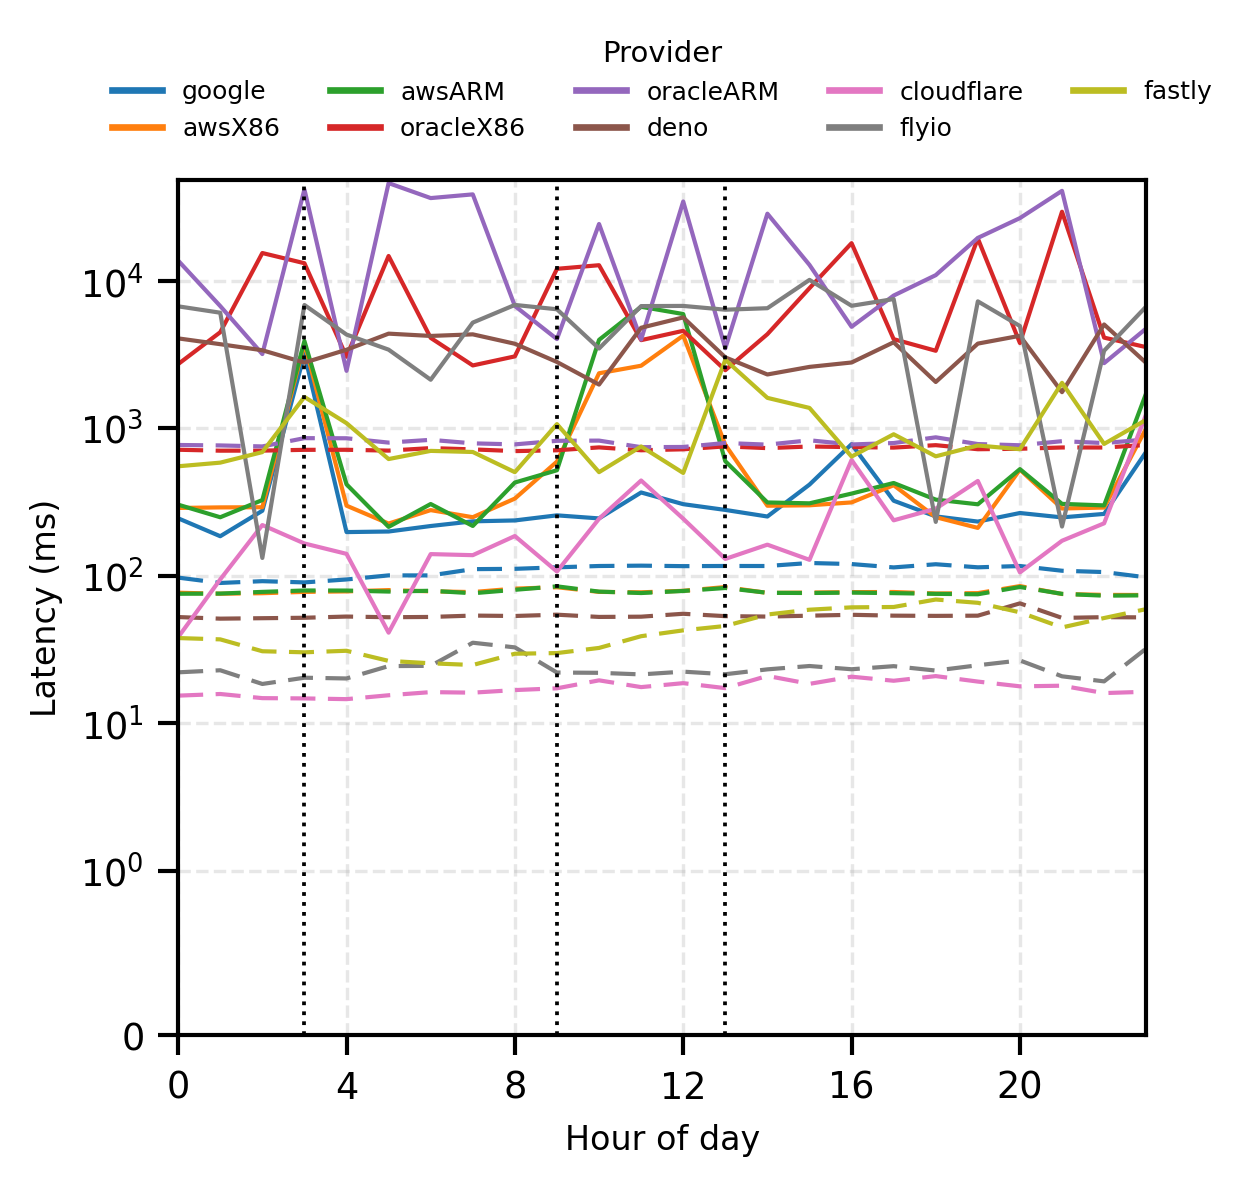

In [9]:
# Combined intraday tail-latency lineplot (all providers, warmstart)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

if "cnx" not in globals():
    import sqlite3
    cnx = sqlite3.connect("../data.db")

providers = ["google", "awsX86", "awsARM", "oracleX86", "oracleARM", "deno", "cloudflare", "flyio", "fastly"]
plot_rows = []

for provider in providers:
    if provider == "fastly":
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
        """
    else:
        query = """
            SELECT date_time, http_req_waiting
            FROM data
            WHERE provider = ?
              AND experiment = 'warmstart'
              AND cold_starts = 0
        """

    df_provider = pd.read_sql_query(query, cnx, params=[provider])
    if df_provider.empty:
        continue

    df_provider["http_req_waiting"] = pd.to_numeric(df_provider["http_req_waiting"], errors="coerce")
    df_provider["ts"] = pd.to_datetime(
        df_provider["date_time"],
        format="%Y-%m-%dT%H-%M-%S",
        errors="coerce",
    )
    df_provider = df_provider.dropna(subset=["http_req_waiting", "ts"])
    if df_provider.empty:
        continue

    df_provider["hour"] = df_provider["ts"].dt.hour

    hourly_stats = (
        df_provider.groupby("hour", as_index=False)["http_req_waiting"]
        .agg(
            p99=lambda s: s.quantile(0.99),
            p9999=lambda s: s.quantile(0.9999),
        )
        .sort_values("hour")
        .reset_index(drop=True)
    )

    if hourly_stats.empty:
        continue

    hourly_long = hourly_stats.melt(
        id_vars="hour",
        value_vars=["p99", "p9999"],
        var_name="percentile",
        value_name="latency_ms",
    )
    hourly_long["provider"] = provider
    plot_rows.append(hourly_long)

if not plot_rows:
    print("No data available for the selected providers/filters.")
else:
    plot_df = pd.concat(plot_rows, ignore_index=True)
    plot_df["percentile"] = plot_df["percentile"].map({"p99": "p99", "p9999": "p99.99"})

    # Stable provider colors so the custom legend matches line colors.
    provider_palette = dict(zip(providers, sns.color_palette("tab10", n_colors=len(providers))))

    # Compact sizing for a single-column figure in a two-column paper.
    with sns.plotting_context("paper", rc={"font.size": 8, "axes.labelsize": 8, "axes.titlesize": 9, "legend.fontsize": 6, "legend.title_fontsize": 7}):
        plt.figure(figsize=(4.2, 4), dpi=300)
        sns.lineplot(
            data=plot_df,
            x="hour",
            y="latency_ms",
            hue="provider",
            style="percentile",
            style_order=["p99", "p99.99"],
            dashes={"p99": (6, 3), "p99.99": ""},
            palette=provider_palette,
            linewidth=1.0,
            legend=False,
        )

        plt.xlabel("Hour of day")
        plt.ylabel("Latency (ms)")
        plt.yscale("symlog", linthresh=1.0)
        plt.ylim(bottom=0)
        plt.xlim(0, 23)
        plt.xticks(range(0, 24, 4))
        plt.grid(True, linestyle="--", alpha=0.3)

        for x in [3, 9, 13]:
            plt.axvline(x=x, color="black", linestyle=":", linewidth=0.9)

        provider_handles = [
            Line2D([0], [0], color=provider_palette[p], lw=1.6, linestyle="-", label=p)
            for p in providers
        ]
        plt.legend(
            handles=provider_handles,
            title="Provider",
            loc="lower center",
            bbox_to_anchor=(0.5, 1.02),
            ncol=5,
            frameon=False,
        )
        plt.tight_layout()
        plt.show()